# ID2223 Lab 1: Building and Evaluating CNNs on CIFAR-10
**Group 11** · Rui Zhang (rzha@kth.se)

This notebook contains the code, configuration and executed results for Tasks 1-6 and both optional challenges. The discussion of the results is in the accompanying PDF report; the markdown here only explains what each cell does and why.

## Reproduction
* Environment used for the submitted run: Python 3.9.13, PyTorch 2.5.1 (CUDA 12.1), torchvision 0.20.1, NumPy, pandas, scikit-learn, matplotlib. GPU: NVIDIA GeForce RTX 4060 Laptop (8 GB). The exact versions are printed by the first code cell.
* CIFAR-10 is loaded with `torchvision.datasets.CIFAR10` into `data/` (downloaded if missing). Challenge 2 also downloads the CIFAR-10.1 v6 test set from its GitHub repository.
* Run all cells from top to bottom. Every training run writes its configuration, per-epoch history and best checkpoint to `runs/<run name>/`. If a folder with an identical configuration exists, the run is loaded instead of retrained, so the notebook can be re-executed cheaply. Delete `runs/` to retrain everything.
* All training is deterministic on a given GPU and software stack (fixed seeds, deterministic cuDNN, `torch.use_deterministic_algorithms(True)`), see the check at the end of the Task 2 setup.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # needed for deterministic cuBLAS

import copy, hashlib, json, math, platform, random, time, urllib.request, warnings
from collections import OrderedDict
warnings.filterwarnings("ignore", message="Pandas requires version")  # old numexpr/bottleneck in the conda env
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.transforms import functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
AMP_DTYPE = torch.bfloat16  # mixed precision for training and evaluation, see Task 6 for FP32 timing

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

DATA_ROOT = Path("data")
RUN_ROOT = Path("runs")
RUN_ROOT.mkdir(exist_ok=True)
REUSE_RUNS = True

print("Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else platform.processor())

Python 3.9.13 | torch 2.5.1+cu121 | torchvision 0.20.1+cu121
Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


## Task 1. Study and Prepare the Data
### 1.1 Load CIFAR-10 and look at the classes
The 50,000 labelled training images are the development data. The 10,000 official test images are loaded here but only used for the final evaluation of frozen models (Task 5 onwards).

In [2]:
def load_cifar10(train):
    try:
        return datasets.CIFAR10(DATA_ROOT, train=train, download=False)
    except RuntimeError:
        return datasets.CIFAR10(DATA_ROOT, train=train, download=True)

dev_set = load_cifar10(train=True)
test_set = load_cifar10(train=False)
class_names = dev_set.classes
X_dev, y_dev = dev_set.data, np.asarray(dev_set.targets, dtype=np.int64)
X_test, y_test = test_set.data, np.asarray(test_set.targets, dtype=np.int64)

print("development images:", X_dev.shape, X_dev.dtype, "| test images:", X_test.shape)
print("pixel range:", X_dev.min(), "-", X_dev.max())
display(pd.DataFrame({
    "class": class_names,
    "development": np.bincount(y_dev, minlength=10),
    "test": np.bincount(y_test, minlength=10),
}))

development images: (50000, 32, 32, 3) uint8 | test images: (10000, 32, 32, 3)
pixel range: 0 - 255


,class,development,test
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000


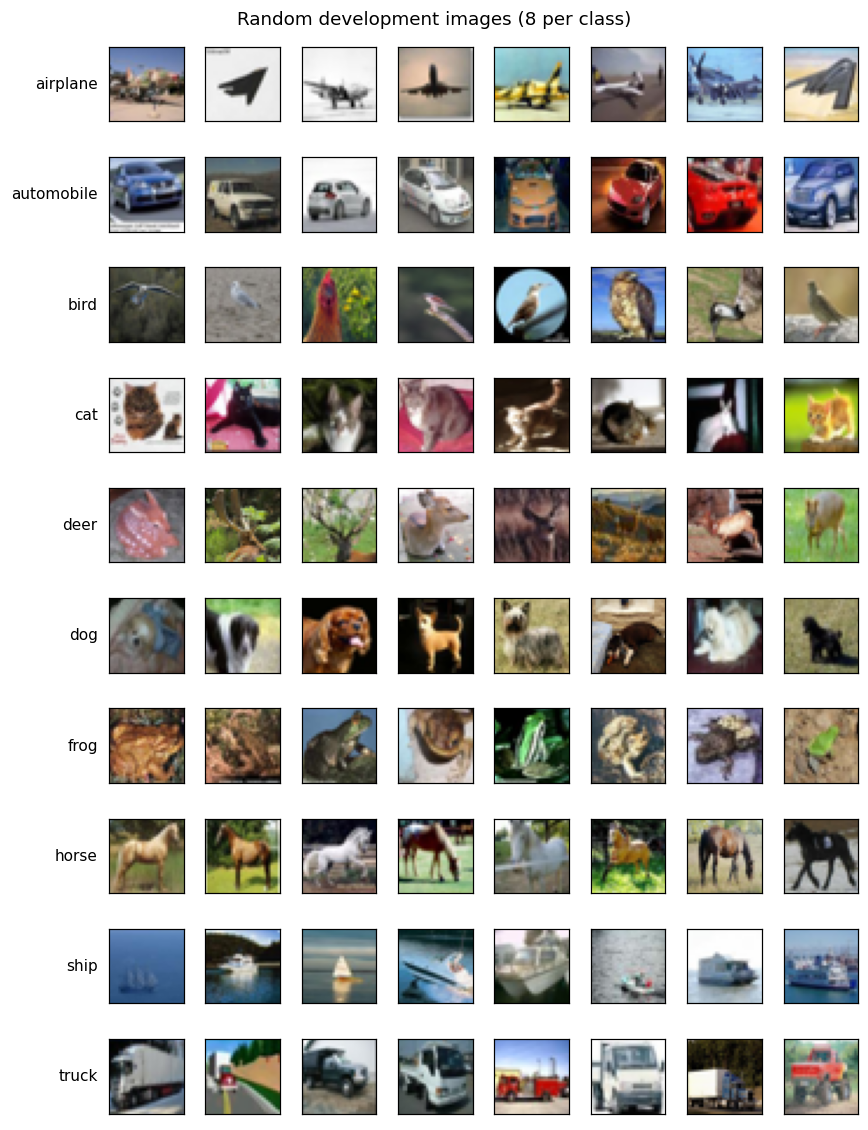

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
for c in range(10):
    picks = rng.choice(np.flatnonzero(y_dev == c), size=8, replace=False)
    for k, idx in enumerate(picks):
        ax = axes[c, k]
        ax.imshow(X_dev[idx])
        ax.set_xticks([]); ax.set_yticks([])
        if k == 0:
            ax.set_ylabel(class_names[c], rotation=0, ha="right", va="center")
fig.suptitle("Random development images (8 per class)")
fig.tight_layout()
plt.show()

### 1.2 Per-class colour statistics and duplicates
The mean image of each class shows how much of the class is carried by background and colour rather than shape (e.g. blue backgrounds for airplanes and ships). I also check for exact duplicate images inside the development set and between development and test data.

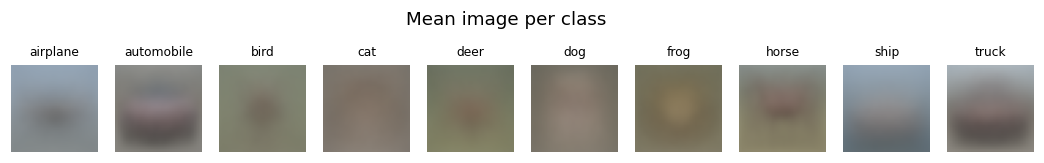

,mean R,mean G,mean B
airplane,0.5257,0.5603,0.5889
automobile,0.4712,0.4545,0.4472
bird,0.4892,0.4915,0.4240
cat,0.4955,0.4564,0.4155
deer,0.4716,0.4652,0.3782
dog,0.4999,0.4646,0.4165
frog,0.4701,0.4384,0.3452
horse,0.5020,0.4799,0.4169
ship,0.4902,0.5254,0.5547
truck,0.4987,0.4853,0.4781


exact duplicates inside development set: 0
exact duplicates inside test set: 0
test images that also appear in the development set: 0


In [4]:
class_means = np.stack([X_dev[y_dev == c].mean(axis=0) for c in range(10)]) / 255
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for c, ax in enumerate(axes):
    ax.imshow(class_means[c])
    ax.set_title(class_names[c], fontsize=8)
    ax.axis("off")
fig.suptitle("Mean image per class", y=1.05)
plt.show()

display(pd.DataFrame(class_means.mean(axis=(1, 2)), index=class_names, columns=["mean R", "mean G", "mean B"]))

dev_hash = [hashlib.md5(img.tobytes()).hexdigest() for img in X_dev]
test_hash = [hashlib.md5(img.tobytes()).hexdigest() for img in X_test]
print("exact duplicates inside development set:", len(dev_hash) - len(set(dev_hash)))
print("exact duplicates inside test set:", len(test_hash) - len(set(test_hash)))
print("test images that also appear in the development set:", len(set(dev_hash) & set(test_hash)))

### 1.3 Splits
A stratified 45,000 / 5,000 split of the development images gives the training and validation sets (seed 2223, same as Part A). The validation set is used for checkpoint selection and every design decision; the test set is not used for any decision.

`train_eval` is a fixed stratified subset of 5,000 training images. After each epoch it is evaluated in eval mode without augmentation, so training and validation curves are measured the same way (the running training loss is affected by dropout, augmentation and the weights changing during the epoch).

In [5]:
SPLIT_SEED = 2223
train_ids, val_ids = train_test_split(
    np.arange(len(X_dev)), test_size=5000, stratify=y_dev, random_state=SPLIT_SEED)
train_ids, val_ids = np.sort(train_ids), np.sort(val_ids)
train_eval_ids, _ = train_test_split(
    train_ids, train_size=5000, stratify=y_dev[train_ids], random_state=SPLIT_SEED)
train_eval_ids = np.sort(train_eval_ids)
assert set(train_ids).isdisjoint(val_ids)

np.savez(RUN_ROOT / "split_ids.npz", train=train_ids, val=val_ids, train_eval=train_eval_ids)
display(pd.DataFrame({
    "train": np.bincount(y_dev[train_ids], minlength=10),
    "val": np.bincount(y_dev[val_ids], minlength=10),
    "train_eval": np.bincount(y_dev[train_eval_ids], minlength=10),
}, index=class_names).T)

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500
val,500,500,500,500,500,500,500,500,500,500
train_eval,500,500,500,500,500,500,500,500,500,500


### 1.4 Preprocessing
Both architectures are used with the native 32x32 resolution (the A9 adaptations were designed for it), so no resizing is needed. The only fixed preprocessing is per-channel standardisation with statistics computed on the 45,000 training images.

Images are kept as `uint8` tensors on the GPU (about 200 MB for all splits). A batch is converted to floats in [0, 1] and the standardisation is the first layer of every model (`Normalize`). This keeps the whole pipeline differentiable with respect to raw pixels, which is needed for the adversarial attack in Task 5, and it means corruptions and attacks can be defined directly in pixel space. Data augmentation is applied per batch on the GPU during training only (Task 4).

In [6]:
channel_sum = np.zeros(3)
channel_sq_sum = np.zeros(3)
for start in range(0, len(train_ids), 5000):
    px = X_dev[train_ids[start:start + 5000]].astype(np.float64) / 255
    channel_sum += px.sum(axis=(0, 1, 2))
    channel_sq_sum += np.square(px).sum(axis=(0, 1, 2))
n_px = len(train_ids) * 32 * 32
MEAN = channel_sum / n_px
STD = np.sqrt(channel_sq_sum / n_px - MEAN ** 2)
display(pd.DataFrame({"mean": MEAN, "std": STD}, index=["red", "green", "blue"]))


@dataclass
class Split:
    x: torch.Tensor   # uint8, N x 3 x 32 x 32, on the device
    y: torch.Tensor   # int64 labels, on the device
    ids: np.ndarray   # index into the original CIFAR-10 array (dev or test)


def make_split(X, y, ids):
    x = torch.from_numpy(X[ids]).permute(0, 3, 1, 2).contiguous().to(device)
    return Split(x, torch.as_tensor(y[ids], dtype=torch.long, device=device), np.asarray(ids))


splits = {
    "train": make_split(X_dev, y_dev, train_ids),
    "train_eval": make_split(X_dev, y_dev, train_eval_ids),
    "val": make_split(X_dev, y_dev, val_ids),
    "test": make_split(X_test, y_test, np.arange(len(X_test))),
}


def to_float(x):
    """uint8 batch -> float in [0, 1], channels_last for faster convolutions."""
    if x.dtype == torch.uint8:
        x = x.float().div_(255)
    return x.contiguous(memory_format=torch.channels_last)


class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1))

    def forward(self, x):
        return (x - self.mean) / self.std


print({k: tuple(v.x.shape) for k, v in splits.items()})

,mean,std
red,0.4913,0.2470
green,0.4822,0.2434
blue,0.4464,0.2615


{'train': (45000, 3, 32, 32), 'train_eval': (5000, 3, 32, 32), 'val': (5000, 3, 32, 32), 'test': (10000, 3, 32, 32)}


## Task 2. Implement and Compare the Models
### 2.1 Architectures
Both networks follow the CIFAR-10 adaptations in Part A9 and are built only from basic PyTorch layers.

**AlexNet.** Five 3x3 convolutions (64-192-384-256-256 channels) with ReLU, three 2x2 max-pools (32 → 16 → 8 → 4) and three fully connected layers (4096 → 1024 → 512 → 10) with dropout after the first two. Compared with the original: 3x3 stride-1 kernels instead of 11x11/5x5 with stride 4, 2x2 instead of overlapping 3x3 pooling, no local response normalisation, much smaller FC layers (1024/512 instead of 4096/4096) and 10 outputs. `width` scales all conv and FC widths together and is used in Task 3.

**ResNet-18.** A 3x3 stem (64 channels, stride 1, no max-pool) followed by four stages of two `BasicBlock`s (64, 128, 256, 512 channels; stages 2-4 halve the resolution with a stride-2 first convolution and a 1x1 projection shortcut), global average pooling and one linear layer. `ResNetCifar` also builds a 1-block-per-stage ResNet-10 (Task 3), the deeper ResNet-34 (3, 4, 6, 3 blocks per stage) and *plain* versions of the 18- and 34-layer networks with the same layers but without shortcuts, which are used below to isolate the effect of the residual connections.

Global average pooling is written as `x.mean((2, 3))` because the CUDA backward of `AdaptiveAvgPool2d` is not deterministic. Convolutions use He (Kaiming) normal initialisation, linear layers keep the PyTorch default.

In [7]:
class AlexNetCifar(nn.Module):
    def __init__(self, width=1.0, dropout=0.5, num_classes=10):
        super().__init__()
        c1, c2, c3, c4, c5 = (int(round(c * width)) for c in (64, 192, 384, 256, 256))
        f1, f2 = int(round(1024 * width)), int(round(512 * width))
        self.features = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c3, c4, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c4, c5, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c5 * 4 * 4, f1), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(f1, f2), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(f2, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.residual = residual
        self.shortcut = nn.Identity()
        if residual and (stride != 1 or in_ch != out_ch):
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))      # no ReLU before the addition
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class GlobalAvgPool(nn.Module):
    def forward(self, x):
        return x.mean(dim=(2, 3))


class ResNetCifar(nn.Module):
    def __init__(self, blocks=(2, 2, 2, 2), width=64, residual=True, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU(inplace=True))
        in_ch, stages = width, []
        for i, n_blocks in enumerate(blocks):
            out_ch = width * 2 ** i
            layers = []
            for j in range(n_blocks):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, out_ch, stride, residual))
                in_ch = out_ch
            stages.append(nn.Sequential(*layers))
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.pool = GlobalAvgPool()
        self.fc = nn.Linear(in_ch, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.fc(self.pool(x))


def init_weights(module):
    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)


ARCHS = {
    "alexnet": lambda c: AlexNetCifar(width=c.width, dropout=c.dropout),
    "resnet18": lambda c: ResNetCifar((2, 2, 2, 2), width=int(round(64 * c.width))),
    "resnet10": lambda c: ResNetCifar((1, 1, 1, 1), width=int(round(64 * c.width))),
    "plain18": lambda c: ResNetCifar((2, 2, 2, 2), width=int(round(64 * c.width)), residual=False),
    "resnet34": lambda c: ResNetCifar((3, 4, 6, 3), width=int(round(64 * c.width))),
    "plain34": lambda c: ResNetCifar((3, 4, 6, 3), width=int(round(64 * c.width)), residual=False),
}


def build_model(cfg):
    net = ARCHS[cfg.arch](cfg)
    init_weights(net)
    model = nn.Sequential(OrderedDict(normalize=Normalize(MEAN, STD), net=net))
    return model.to(device).to(memory_format=torch.channels_last)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### 2.2 Layers, feature-map shapes and parameter counts
Forward hooks record the output shape of every layer for one 32x32 input. Parameter counts are per layer; for ResNet a row is one residual block (two convolutions, two BN layers and the projection shortcut when present).

In [8]:
def layer_table(net):
    if isinstance(net, AlexNetCifar):
        named = [(f"features.{i}", m) for i, m in enumerate(net.features)] + \
                [(f"classifier.{i}", m) for i, m in enumerate(net.classifier)]
    else:
        named = [("stem", net.stem)]
        for s in range(1, 5):
            named += [(f"stage{s}.{j}", b) for j, b in enumerate(getattr(net, f"stage{s}"))]
        named += [("pool", net.pool), ("fc", net.fc)]
    rows, hooks = [], []
    for name, m in named:
        def hook(mod, inp, out, name=name):
            rows.append({"layer": name, "type": type(mod).__name__,
                         "output shape": tuple(out.shape[1:]),
                         "params": sum(p.numel() for p in mod.parameters())})
        hooks.append(m.register_forward_hook(hook))
    net.eval()
    with torch.no_grad():
        net(torch.zeros(1, 3, 32, 32, device=next(net.parameters()).device))
    for h in hooks:
        h.remove()
    table = pd.DataFrame(rows)
    return table


@dataclass(frozen=True)
class RunConfig:
    name: str
    arch: str
    width: float = 1.0
    dropout: float = 0.5          # AlexNet only (ResNet has no dropout)
    weight_decay: float = 5e-4    # L2 strength lambda on conv/linear weights
    augment: str = "none"         # key of AUGMENTATIONS (Task 4)
    epochs: int = 30
    batch_size: int = 128
    lr: float = 0.05
    warmup_epochs: int = 2
    seed: int = 0
    teacher: str = ""             # Challenge 1 (distillation)
    kd_temperature: float = 4.0
    kd_alpha: float = 0.9


for arch in ["alexnet", "resnet18"]:
    net = build_model(RunConfig("probe", arch)).net
    table = layer_table(net)
    print(f"{arch}: {count_params(net):,} trainable parameters")
    display(table)
    del net

alexnet: 6,976,842 trainable parameters


,layer,type,output shape,params
0,features.0,Conv2d,"(64, 32, 32)",1792
1,features.1,ReLU,"(64, 32, 32)",0
2,features.2,MaxPool2d,"(64, 16, 16)",0
3,features.3,Conv2d,"(192, 16, 16)",110784
4,features.4,ReLU,"(192, 16, 16)",0
5,features.5,MaxPool2d,"(192, 8, 8)",0
6,features.6,Conv2d,"(384, 8, 8)",663936
7,features.7,ReLU,"(384, 8, 8)",0
8,features.8,Conv2d,"(256, 8, 8)",884992
9,features.9,ReLU,"(256, 8, 8)",0


resnet18: 11,173,962 trainable parameters


,layer,type,output shape,params
0,stem,Sequential,"(64, 32, 32)",1856
1,stage1.0,BasicBlock,"(64, 32, 32)",73984
2,stage1.1,BasicBlock,"(64, 32, 32)",73984
3,stage2.0,BasicBlock,"(128, 16, 16)",230144
4,stage2.1,BasicBlock,"(128, 16, 16)",295424
5,stage3.0,BasicBlock,"(256, 8, 8)",919040
6,stage3.1,BasicBlock,"(256, 8, 8)",1180672
7,stage4.0,BasicBlock,"(512, 4, 4)",3673088
8,stage4.1,BasicBlock,"(512, 4, 4)",4720640
9,pool,GlobalAvgPool,"(512,)",0


### 2.3 Training procedure
All runs use the same procedure so that differences come from the configuration:
* SGD with Nesterov momentum 0.9, batch size 128, cross-entropy on raw logits.
* Learning rate: linear warm-up for 2 epochs, then cosine decay to zero at the last step. The peak learning rate is chosen per architecture family with a short validation check (2.4).
* L2 regularisation through SGD weight decay, applied to conv and linear weights only (not biases or BN parameters). For SGD this is exactly the gradient of $\frac{\lambda}{2}\sum_W\|W\|_F^2$ from Part A. Default $\lambda = 5\cdot10^{-4}$.
* Mixed precision (bfloat16 autocast) for speed; parameters and optimizer state stay in FP32.
* Every epoch the model is evaluated on `train_eval` and `val`. The checkpoint with the highest validation accuracy is kept (`best.pt`).
* Compute budget: 30 epochs (1.35 M training samples) per run, on one RTX 4060 Laptop GPU. Training time counts only the optimisation steps; evaluation time is reported separately.

The data order and the random augmentation are drawn from a `torch.Generator` seeded with the run seed, and the model is initialised after `torch.manual_seed(seed)`, so a run is fully determined by its config.

In [9]:
AUGMENTATIONS = {"none": lambda x, gen: x}   # more are registered in Task 4


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.inference_mode()
def predict_logits(model, x, batch_size=1000):
    model.eval()
    outs = []
    for i in range(0, len(x), batch_size):
        with torch.autocast(device.type, dtype=AMP_DTYPE):
            outs.append(model(to_float(x[i:i + batch_size])).float())
    return torch.cat(outs)


def evaluate(model, x, y):
    logits = predict_logits(model, x)
    pred = logits.argmax(1)
    return {"ce": F.cross_entropy(logits, y).item(),
            "accuracy": (pred == y).float().mean().item(),
            "logits": logits, "pred": pred}


def lr_factor(total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * t))
    return f


@dataclass
class Run:
    cfg: RunConfig
    model: nn.Module
    history: pd.DataFrame
    summary: dict


RUNS = {}


def load_cached(cfg):
    run_dir = RUN_ROOT / cfg.name
    try:
        if json.loads((run_dir / "config.json").read_text()) != asdict(cfg):
            return None
        model = build_model(cfg)
        model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device, weights_only=True))
        history = pd.read_csv(run_dir / "history.csv")
        summary = json.loads((run_dir / "summary.json").read_text())
        return Run(cfg, model, history, summary)
    except FileNotFoundError:
        return None


def train_run(cfg, print_every=5):
    if REUSE_RUNS and (cached := load_cached(cfg)) is not None:
        RUNS[cfg.name] = cached
        print(f"[{cfg.name}] loaded from cache: best val acc {cached.summary['best_val_accuracy']:.4f} "
              f"(epoch {cached.summary['best_epoch']})")
        return cached

    if device.type == "cuda":
        mem_before = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
    set_seed(cfg.seed)
    model = build_model(cfg)
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    optimizer = torch.optim.SGD(
        [{"params": decay, "weight_decay": cfg.weight_decay}, {"params": no_decay, "weight_decay": 0.0}],
        lr=cfg.lr, momentum=0.9, nesterov=True)
    train = splits["train"]
    n = len(train.y)
    steps_per_epoch = math.ceil(n / cfg.batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lr_factor(cfg.epochs * steps_per_epoch, cfg.warmup_epochs * steps_per_epoch))
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    augment = AUGMENTATIONS[cfg.augment]
    teacher = RUNS[cfg.teacher].model.eval() if cfg.teacher else None
    first_conv = next(p for p in model.parameters() if p.ndim == 4)
    last_linear = [p for p in model.parameters() if p.ndim == 2][-1]

    history, best_acc, best_state, diverged = [], -1.0, None, False
    train_seconds = eval_seconds = 0.0
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        synchronize(); t0 = time.perf_counter()
        order = torch.randperm(n, device=device, generator=gen)
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        grad_first, grad_last, n_grad = torch.zeros((), device=device), torch.zeros((), device=device), 0
        for step, start in enumerate(range(0, n, cfg.batch_size)):
            idx = order[start:start + cfg.batch_size]
            xb, yb = augment(to_float(train.x[idx]), gen), train.y[idx]
            with torch.autocast(device.type, dtype=AMP_DTYPE):
                logits = model(xb)
                ce = F.cross_entropy(logits.float(), yb)
                loss = ce
                if teacher is not None:
                    with torch.no_grad():
                        t_logits = teacher(xb).float()
                    T = cfg.kd_temperature
                    kd = F.kl_div(F.log_softmax(logits.float() / T, 1), F.softmax(t_logits / T, 1),
                                  reduction="batchmean") * T * T
                    loss = cfg.kd_alpha * kd + (1 - cfg.kd_alpha) * ce
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            if step % 25 == 0:
                grad_first += first_conv.grad.norm(); grad_last += last_linear.grad.norm(); n_grad += 1
            optimizer.step()
            scheduler.step()
            loss_sum += ce.detach() * len(yb)
            correct += (logits.argmax(1) == yb).sum()
        synchronize(); train_seconds += time.perf_counter() - t0
        running_ce = loss_sum.item() / n
        if not math.isfinite(running_ce):
            diverged = True
            print(f"[{cfg.name}] diverged in epoch {epoch}")
            break

        t1 = time.perf_counter()
        tr = evaluate(model, splits["train_eval"].x, splits["train_eval"].y)
        va = evaluate(model, splits["val"].x, splits["val"].y)
        eval_seconds += time.perf_counter() - t1
        history.append({
            "epoch": epoch, "lr": optimizer.param_groups[0]["lr"],
            "running_train_ce": running_ce, "running_train_accuracy": correct.item() / n,
            "train_ce": tr["ce"], "train_accuracy": tr["accuracy"],
            "val_ce": va["ce"], "val_accuracy": va["accuracy"],
            "grad_norm_first_conv": (grad_first / n_grad).item(),
            "grad_norm_last_linear": (grad_last / n_grad).item(),
            "train_seconds": train_seconds,
        })
        if va["accuracy"] > best_acc:
            best_acc, best_epoch = va["accuracy"], epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch % print_every == 0 or epoch == cfg.epochs:
            print(f"[{cfg.name}] epoch {epoch:2d}  train acc {tr['accuracy']:.4f}  val acc {va['accuracy']:.4f}  "
                  f"val ce {va['ce']:.3f}  ({train_seconds:.0f}s)")

    # memory added by this run (model, optimizer state, activations), not the data or other cached models
    peak_mb = (torch.cuda.max_memory_allocated() - mem_before) / 2 ** 20 if device.type == "cuda" else float("nan")
    history = pd.DataFrame(history)
    if best_state is not None:
        model.load_state_dict(best_state)
    summary = {
        "params": count_params(model.net),
        "best_epoch": best_epoch if best_state else None,
        "best_val_accuracy": best_acc,
        "final_val_accuracy": history.val_accuracy.iloc[-1] if len(history) else float("nan"),
        "train_seconds": train_seconds, "eval_seconds": eval_seconds,
        "peak_memory_mb": peak_mb,
        "samples_seen": len(history) * n, "diverged": diverged,
    }
    run_dir = RUN_ROOT / cfg.name
    run_dir.mkdir(parents=True, exist_ok=True)
    history.to_csv(run_dir / "history.csv", index=False)
    (run_dir / "summary.json").write_text(json.dumps(summary, indent=2))
    if best_state is not None:
        torch.save(best_state, run_dir / "best.pt")
    (run_dir / "config.json").write_text(json.dumps(asdict(cfg), indent=2))
    run = Run(cfg, model, history, summary)
    RUNS[cfg.name] = run
    return run

**Reproducibility check (Task 1, randomness).** Two short runs with the same config must give bit-identical weights; a different seed must not.

In [10]:
def short_training(seed, steps=40):
    set_seed(seed)
    model = build_model(RunConfig("check", "resnet10", width=0.5))
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    gen = torch.Generator(device=device).manual_seed(seed)
    order = torch.randperm(len(splits["train"].y), device=device, generator=gen)
    model.train()
    for s in range(steps):
        idx = order[s * 128:(s + 1) * 128]
        with torch.autocast(device.type, dtype=AMP_DTYPE):
            loss = F.cross_entropy(model(to_float(splits["train"].x[idx])).float(), splits["train"].y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])

w_a, w_b, w_c = short_training(0), short_training(0), short_training(1)
print("same seed, identical weights:", torch.equal(w_a, w_b))
print("different seed, max |difference|:", (w_a - w_c).abs().max().item())
del w_a, w_b, w_c

same seed, identical weights: True
different seed, max |difference|: 1.009243369102478


### 2.4 Peak learning rate
AlexNet has no batch normalisation and is more sensitive to the step size than ResNet. I compare peak learning rates on a factor-of-two grid per architecture with a shortened 10-epoch schedule (seed 0, no augmentation) and use the best one, by validation accuracy, for every later run of that family. This is the only tuning done for the baselines.

In [11]:
LR_CANDIDATES = {"alexnet": [0.01, 0.02, 0.05, 0.1], "resnet18": [0.05, 0.1, 0.2, 0.4, 0.8]}
lr_rows = []
for arch, lrs in LR_CANDIDATES.items():
    for lr in lrs:
        run = train_run(RunConfig(f"lrcheck_{arch}_lr{lr}", arch, lr=lr, epochs=10), print_every=10)
        lr_rows.append({"arch": arch, "lr": lr, "best val acc": run.summary["best_val_accuracy"],
                        "diverged": run.summary["diverged"]})
lr_table = pd.DataFrame(lr_rows)
display(lr_table)
ok = lr_table[~lr_table.diverged]
BEST_LR = {arch: float(g.loc[g["best val acc"].idxmax(), "lr"]) for arch, g in ok.groupby("arch")}
LR = {"alexnet": BEST_LR["alexnet"],
      **{a: BEST_LR["resnet18"] for a in ["resnet18", "resnet10", "plain18", "resnet34", "plain34"]}}
print("chosen peak learning rates:", LR)

[lrcheck_alexnet_lr0.01] loaded from cache: best val acc 0.8010 (epoch 10)
[lrcheck_alexnet_lr0.02] loaded from cache: best val acc 0.8334 (epoch 10)
[lrcheck_alexnet_lr0.05] loaded from cache: best val acc 0.8368 (epoch 10)
[lrcheck_alexnet_lr0.1] loaded from cache: best val acc 0.8342 (epoch 9)
[lrcheck_resnet18_lr0.05] loaded from cache: best val acc 0.8524 (epoch 10)
[lrcheck_resnet18_lr0.1] loaded from cache: best val acc 0.8630 (epoch 10)
[lrcheck_resnet18_lr0.2] loaded from cache: best val acc 0.8746 (epoch 10)
[lrcheck_resnet18_lr0.4] loaded from cache: best val acc 0.8828 (epoch 10)
[lrcheck_resnet18_lr0.8] loaded from cache: best val acc 0.8758 (epoch 10)


,arch,lr,best val acc,diverged
0,alexnet,0.01,0.8010,False
1,alexnet,0.02,0.8334,False
2,alexnet,0.05,0.8368,False
3,alexnet,0.10,0.8342,False
4,resnet18,0.05,0.8524,False
5,resnet18,0.10,0.8630,False
6,resnet18,0.20,0.8746,False
7,resnet18,0.40,0.8828,False
8,resnet18,0.80,0.8758,False


chosen peak learning rates: {'alexnet': 0.05, 'resnet18': 0.4, 'resnet10': 0.4, 'plain18': 0.4, 'resnet34': 0.4, 'plain34': 0.4}


### 2.5 Baselines: AlexNet vs ResNet-18
Both models are trained without augmentation (the "original" training condition used again in Task 4), with weight decay $5\cdot10^{-4}$ and, for AlexNet, dropout 0.5. Three seeds per model show how much of a difference is just run-to-run noise. To see what the residual connections do, ResNet-18 and ResNet-34 are compared with plain networks of the same depth (same layers, no shortcuts), all with the ResNet settings and seed 0.

In [12]:
SEEDS = [0, 1, 2]
def baseline_cfg(arch, seed=0, **kw):
    return RunConfig(f"{arch}_{kw.get('augment', 'none')}_s{seed}", arch, lr=LR[arch], seed=seed, **kw)

for seed in SEEDS:
    train_run(baseline_cfg("alexnet", seed))
    train_run(baseline_cfg("resnet18", seed))
for arch in ["plain18", "resnet34", "plain34"]:
    _ = train_run(baseline_cfg(arch, 0))

[alexnet_none_s0] loaded from cache: best val acc 0.8468 (epoch 24)
[resnet18_none_s0] loaded from cache: best val acc 0.8922 (epoch 29)
[alexnet_none_s1] loaded from cache: best val acc 0.8400 (epoch 30)
[resnet18_none_s1] loaded from cache: best val acc 0.8846 (epoch 26)
[alexnet_none_s2] loaded from cache: best val acc 0.8516 (epoch 30)
[resnet18_none_s2] loaded from cache: best val acc 0.8928 (epoch 28)
[plain18_none_s0] loaded from cache: best val acc 0.8936 (epoch 29)
[resnet34_none_s0] loaded from cache: best val acc 0.8880 (epoch 30)
[plain34_none_s0] loaded from cache: best val acc 0.8748 (epoch 29)


In [13]:
def summary_table(names):
    rows = []
    for name in names:
        r = RUNS[name]
        rows.append({"run": name, "params (M)": r.summary["params"] / 1e6,
                     "best epoch": r.summary["best_epoch"],
                     "train acc @best": r.history.train_accuracy.iloc[r.summary["best_epoch"] - 1],
                     "val acc (best)": r.summary["best_val_accuracy"],
                     "val acc (last)": r.summary["final_val_accuracy"],
                     "train time (s)": r.summary["train_seconds"],
                     "s / epoch": r.summary["train_seconds"] / len(r.history),
                     "peak mem (MB)": r.summary["peak_memory_mb"],
                     "samples seen (M)": r.summary["samples_seen"] / 1e6})
    return pd.DataFrame(rows).set_index("run")


baseline_names = [f"{a}_none_s{s}" for a in ["alexnet", "resnet18"] for s in SEEDS] +                  [f"{a}_none_s0" for a in ["plain18", "resnet34", "plain34"]]
t2 = summary_table(baseline_names)
display(t2)
seed_stats = t2.iloc[:6].groupby(lambda n: n.split("_")[0])[["val acc (best)", "train time (s)"]].agg(["mean", "std"])
display(seed_stats)

,params (M),best epoch,train acc @best,val acc (best),val acc (last),train time (s),s / epoch,peak mem (MB),samples seen (M)
run,,,,,,,,,
alexnet_none_s0,6.9768,24,1.0000,0.8468,0.8460,109.9780,3.6659,417.5557,1.35
alexnet_none_s1,6.9768,30,1.0000,0.8400,0.8400,110.2399,3.6747,419.9932,1.35
alexnet_none_s2,6.9768,30,1.0000,0.8516,0.8516,109.8792,3.6626,418.7744,1.35
resnet18_none_s0,11.1740,29,1.0000,0.8922,0.8912,338.4191,11.2806,828.3062,1.35
resnet18_none_s1,11.1740,26,1.0000,0.8846,0.8830,338.7417,11.2914,829.7046,1.35
resnet18_none_s2,11.1740,28,1.0000,0.8928,0.8896,338.6443,11.2881,828.5796,1.35
plain18_none_s0,11.0001,29,1.0000,0.8936,0.8912,311.3819,10.3794,827.4731,1.35
resnet34_none_s0,21.2821,30,1.0000,0.8880,0.8880,632.6273,21.0876,987.0366,1.35
plain34_none_s0,21.1083,29,0.9982,0.8748,0.8736,596.0940,19.8698,985.6802,1.35


val acc (best)         train time (s)        
                   mean     std           mean     std
run                                                   
alexnet          0.8461  0.0058       110.0324  0.1864
resnet18         0.8899  0.0046       338.6017  0.1655

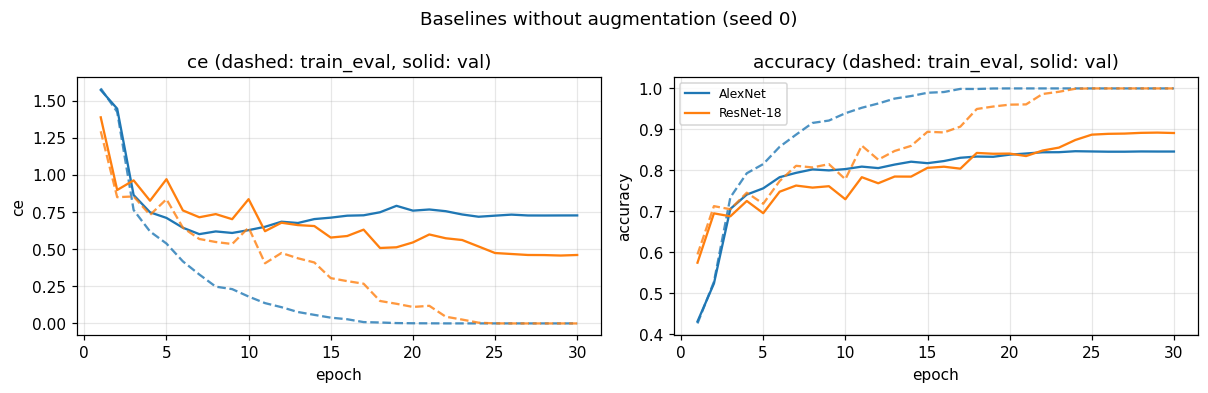

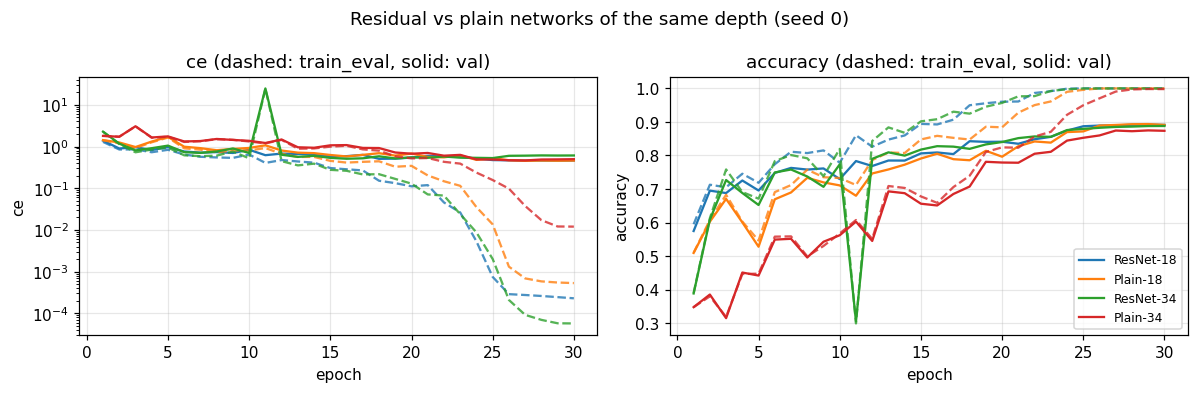

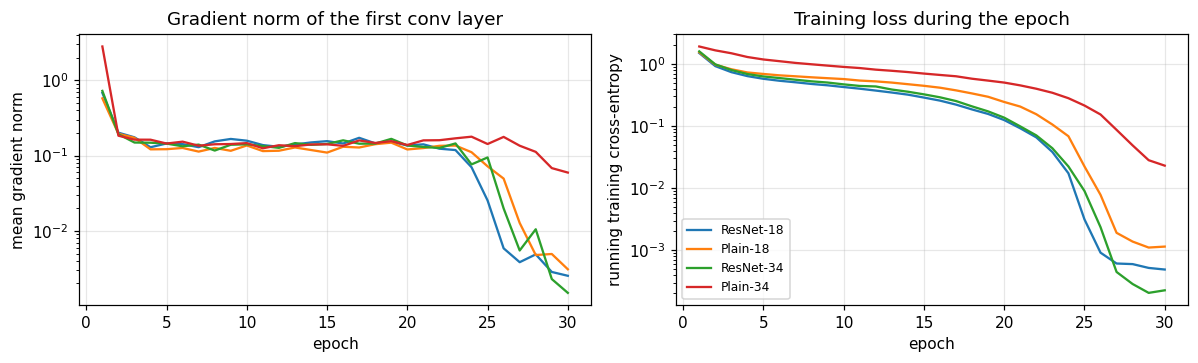

In [14]:
def plot_curves(names, title, labels=None, metrics=("ce", "accuracy"), log_ce=False):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 3.6))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for k, name in enumerate(names):
        h = RUNS[name].history
        label = labels[k] if labels else name
        for ax, m in zip(axes, metrics):
            ax.plot(h.epoch, h[f"train_{m}"], "--", color=colors[k % 10], alpha=0.8)
            ax.plot(h.epoch, h[f"val_{m}"], "-", color=colors[k % 10], label=label)
    for ax, m in zip(axes, metrics):
        ax.set(xlabel="epoch", ylabel=m, title=f"{m} (dashed: train_eval, solid: val)")
        if m == "ce" and log_ce:
            ax.set_yscale("log")
    axes[-1].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_curves(["alexnet_none_s0", "resnet18_none_s0"], "Baselines without augmentation (seed 0)", ["AlexNet", "ResNet-18"])
depth_runs = ["resnet18_none_s0", "plain18_none_s0", "resnet34_none_s0", "plain34_none_s0"]
depth_labels = ["ResNet-18", "Plain-18", "ResNet-34", "Plain-34"]
plot_curves(depth_runs, "Residual vs plain networks of the same depth (seed 0)", depth_labels, log_ce=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for k, (name, label) in enumerate(zip(depth_runs, depth_labels)):
    h = RUNS[name].history
    axes[0].plot(h.epoch, h.grad_norm_first_conv, color=f"C{k}", label=label)
    axes[1].plot(h.epoch, h.running_train_ce, color=f"C{k}", label=label)
axes[0].set(yscale="log", xlabel="epoch", ylabel="mean gradient norm", title="Gradient norm of the first conv layer")
axes[1].set(yscale="log", xlabel="epoch", ylabel="running training cross-entropy", title="Training loss during the epoch")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### 2.6 What the convolutions learn
The first-layer 3x3 filters (shown as RGB patches after min-max scaling) act as colour and edge detectors. Feature maps from successive stages for one validation image show the trade of spatial resolution for more, more abstract channels.

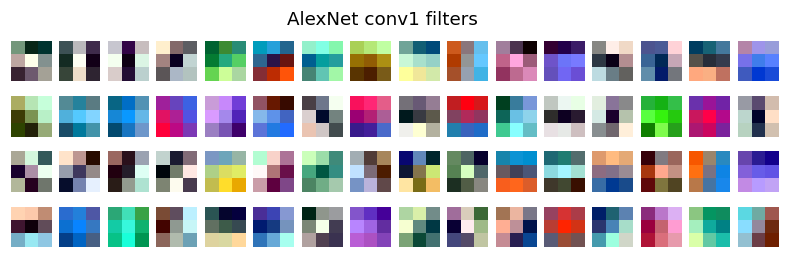

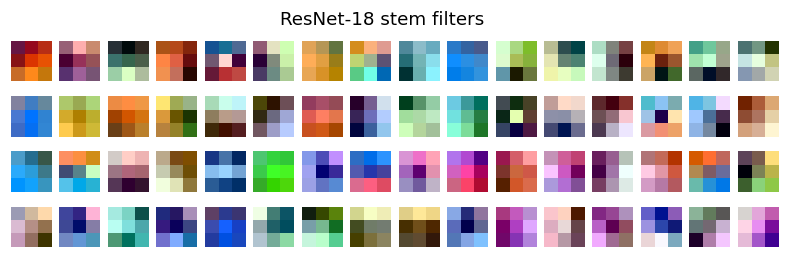

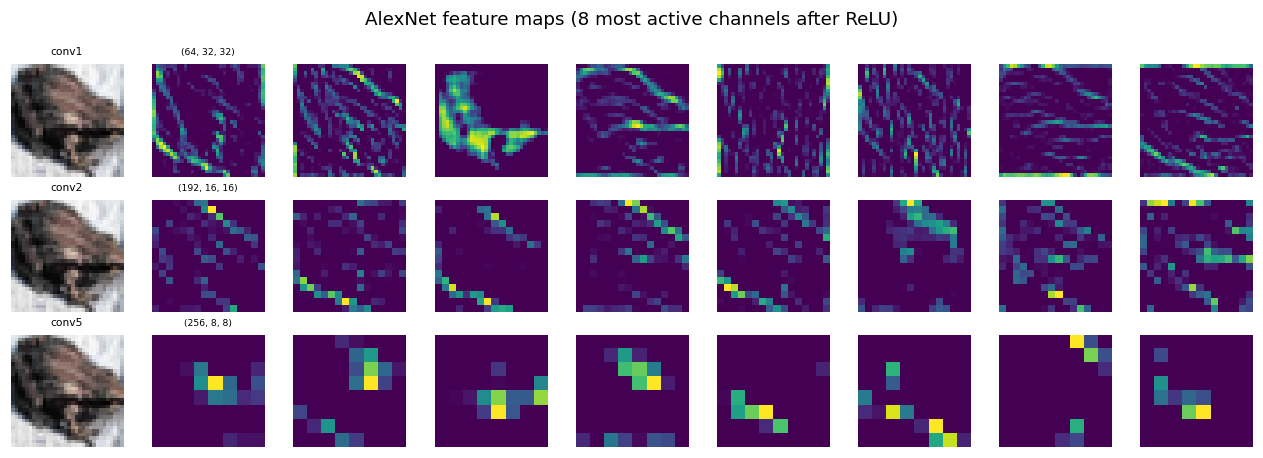

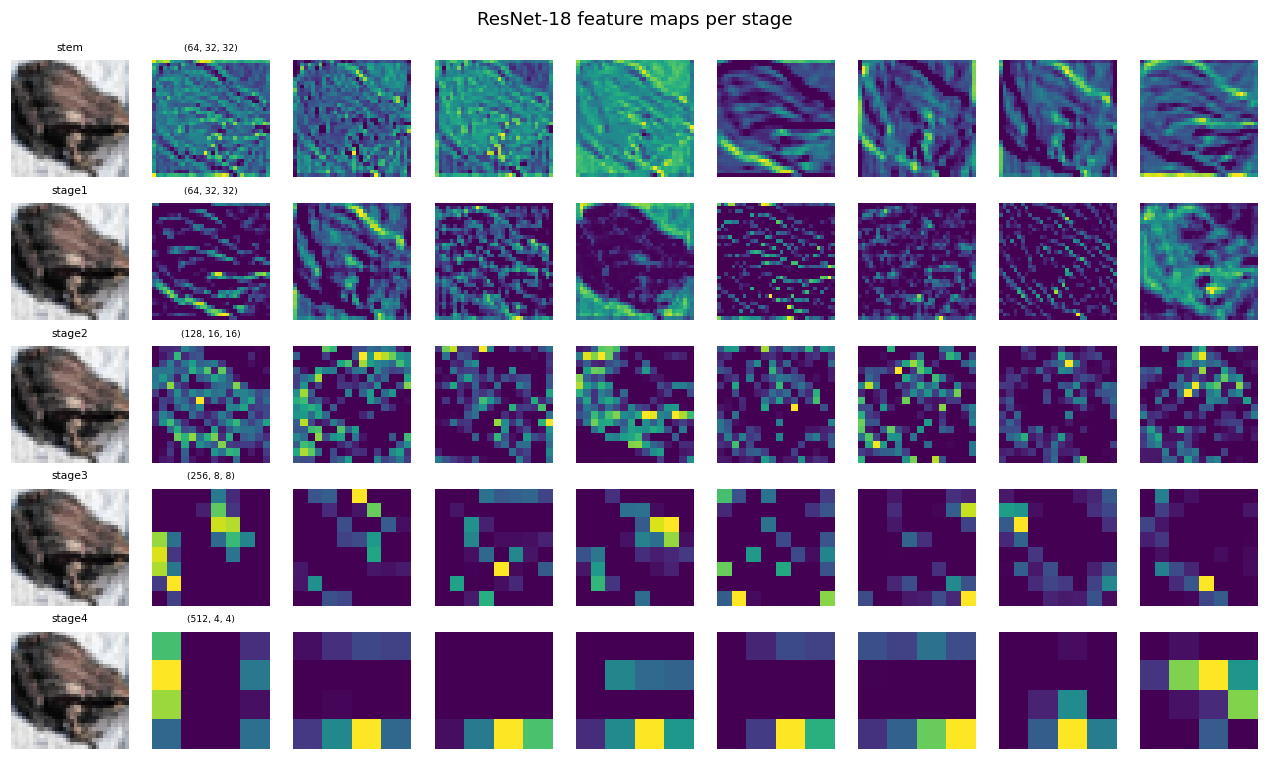

In [15]:
def show_first_filters(model, title, n=64):
    w = next(p for p in model.net.parameters() if p.ndim == 4).detach().float().cpu()[:n]
    w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True) + 1e-8)
    fig, axes = plt.subplots(4, 16, figsize=(9, 2.5))
    for k, ax in enumerate(axes.flat):
        ax.imshow(w[k].permute(1, 2, 0))
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


@torch.no_grad()
def show_feature_maps(model, image, layers, title, n_maps=8):
    feats, hooks = {}, []
    for name, m in layers:
        hooks.append(m.register_forward_hook(lambda mod, i, o, name=name: feats.__setitem__(name, o.float().cpu())))
    model.eval()
    model(to_float(image[None]))
    for h in hooks:
        h.remove()
    fig, axes = plt.subplots(len(layers), n_maps + 1, figsize=(1.3 * (n_maps + 1), 1.4 * len(layers)))
    for r, (name, _) in enumerate(layers):
        axes[r, 0].imshow(image.permute(1, 2, 0).cpu())
        axes[r, 0].set_title(name, fontsize=7)
        f = feats[name][0]
        strongest = f.mean(dim=(1, 2)).argsort(descending=True)[:n_maps]
        for k, ch in enumerate(strongest):
            axes[r, k + 1].imshow(f[ch], cmap="viridis")
            axes[r, k + 1].set_title(f"{tuple(f.shape)}" if k == 0 else "", fontsize=6)
        for ax in axes[r]:
            ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


show_first_filters(RUNS["alexnet_none_s0"].model, "AlexNet conv1 filters")
show_first_filters(RUNS["resnet18_none_s0"].model, "ResNet-18 stem filters")
sample_image = splits["val"].x[7]
a_net = RUNS["alexnet_none_s0"].model.net
show_feature_maps(RUNS["alexnet_none_s0"].model, sample_image,
                  [("conv1", a_net.features[1]), ("conv2", a_net.features[4]), ("conv5", a_net.features[11])],
                  "AlexNet feature maps (8 most active channels after ReLU)")
r_net = RUNS["resnet18_none_s0"].model.net
show_feature_maps(RUNS["resnet18_none_s0"].model, sample_image,
                  [("stem", r_net.stem), ("stage1", r_net.stage1), ("stage2", r_net.stage2),
                   ("stage3", r_net.stage3), ("stage4", r_net.stage4)],
                  "ResNet-18 feature maps per stage")

## Task 3. Investigate Capacity and Regularization
**Design.** The reference is the AlexNet baseline from Task 2 (width 1, dropout 0.5, $\lambda = 5\cdot10^{-4}$, no augmentation, seed 0). Each comparison changes one factor and keeps the data split, learning rate, schedule, 30-epoch budget and seed fixed. Augmentation is off so that the effect of the explicit regularisers is not hidden by it. AlexNet is the main subject because its large fully connected layers overfit and its dropout sits exactly there; ResNet-18 has no dropout layers.

* **Width (capacity):** 0.25, 0.5, 1 and 2 times the A9 channel and FC sizes (about 0.5 M to 28 M parameters).
* **Dropout:** p = 0 (no dropout), 0.3 and 0.5 in both hidden FC layers.
* **L2:** $\lambda$ = 0, $5\cdot10^{-4}$ and $5\cdot10^{-3}$.
* **No regularisation:** dropout 0 and $\lambda$ = 0 together, as an upper bound on overfitting.
* **ResNet capacity:** depth (ResNet-10 with one block per stage vs ResNet-18) and width (base 32 vs 64 channels).

The seed-to-seed standard deviation from Task 2 is the noise level; differences smaller than about two standard deviations are not interpreted.

In [16]:
alex_ref = baseline_cfg("alexnet", 0)
res_ref = baseline_cfg("resnet18", 0)
task3_groups = {
    "AlexNet width": [alex_ref if w == 1.0 else replace(alex_ref, name=f"alexnet_w{w}_none_s0", width=w)
                      for w in (0.25, 0.5, 1.0, 2.0)],
    "AlexNet dropout": [alex_ref if p == 0.5 else replace(alex_ref, name=f"alexnet_p{p}_none_s0", dropout=p)
                        for p in (0.0, 0.3, 0.5)],
    "AlexNet L2": [alex_ref if wd == 5e-4 else replace(alex_ref, name=f"alexnet_wd{wd}_none_s0", weight_decay=wd)
                   for wd in (0.0, 5e-4, 5e-3)],
    "AlexNet no regularisation": [replace(alex_ref, name="alexnet_noreg_none_s0", dropout=0.0, weight_decay=0.0),
                                  alex_ref],
    "ResNet depth and width": [baseline_cfg("resnet10", 0),
                               replace(res_ref, name="resnet18_w0.5_none_s0", width=0.5), res_ref],
}
for cfgs in task3_groups.values():
    for cfg in cfgs:
        train_run(cfg)

[alexnet_w0.25_none_s0] loaded from cache: best val acc 0.8026 (epoch 27)
[alexnet_w0.5_none_s0] loaded from cache: best val acc 0.8348 (epoch 30)
[alexnet_none_s0] loaded from cache: best val acc 0.8468 (epoch 24)
[alexnet_w2.0_none_s0] loaded from cache: best val acc 0.8480 (epoch 19)
[alexnet_p0.0_none_s0] loaded from cache: best val acc 0.8314 (epoch 18)
[alexnet_p0.3_none_s0] loaded from cache: best val acc 0.8392 (epoch 23)
[alexnet_none_s0] loaded from cache: best val acc 0.8468 (epoch 24)
[alexnet_wd0.0_none_s0] loaded from cache: best val acc 0.8304 (epoch 25)
[alexnet_none_s0] loaded from cache: best val acc 0.8468 (epoch 24)
[alexnet_wd0.005_none_s0] loaded from cache: best val acc 0.8432 (epoch 28)
[alexnet_noreg_none_s0] loaded from cache: best val acc 0.8122 (epoch 28)
[alexnet_none_s0] loaded from cache: best val acc 0.8468 (epoch 24)
[resnet10_none_s0] loaded from cache: best val acc 0.8834 (epoch 29)
[resnet18_w0.5_none_s0] loaded from cache: best val acc 0.8780 (epoch

noise level (std of best val acc over 3 seeds):


,mean,std
run,,
alexnet,0.8461,0.0058
resnet18,0.8899,0.0046


AlexNet width


,params (M),best epoch,train acc @best,val acc (best),s / epoch,peak mem (MB),gap,min val ce,epoch of min val ce,last val ce,sum ||W||^2
run,,,,,,,,,,,
alexnet_w0.25_none_s0,0.4379,27,0.9974,0.8026,1.3130,102.2485,0.1948,0.7058,12,0.9981,1194.4795
alexnet_w0.5_none_s0,1.7466,30,1.0000,0.8348,1.3618,194.7788,0.1652,0.6569,10,0.8860,1363.6579
alexnet_none_s0,6.9768,24,1.0000,0.8468,3.6659,417.5557,0.1532,0.6011,7,0.7270,1424.5234
alexnet_w2.0_none_s0,27.8883,19,1.0000,0.8480,11.6995,1017.3892,0.1520,0.6037,6,0.6916,1810.5972


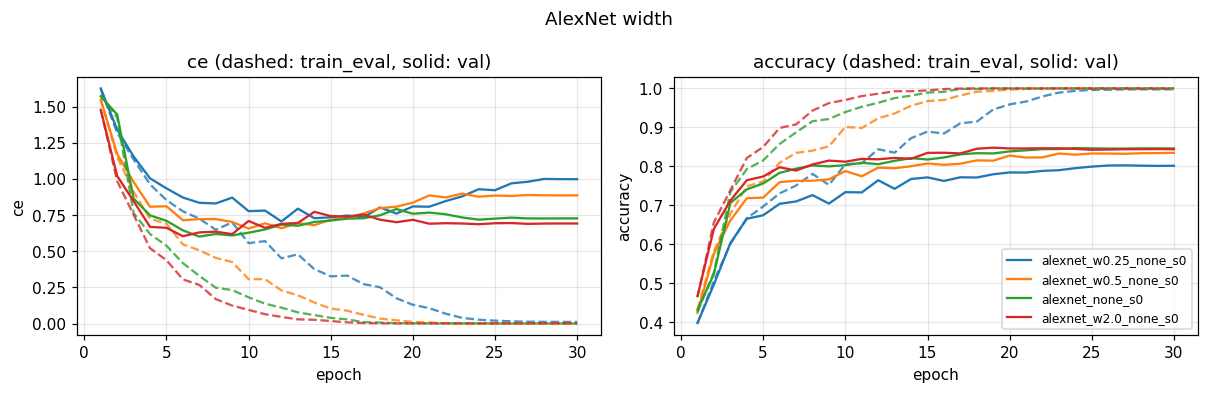

AlexNet dropout


,params (M),best epoch,train acc @best,val acc (best),s / epoch,peak mem (MB),gap,min val ce,epoch of min val ce,last val ce,sum ||W||^2
run,,,,,,,,,,,
alexnet_p0.0_none_s0,6.9768,18,1.0,0.8314,3.6566,419.5557,0.1686,0.6420,7,0.8817,1350.7127
alexnet_p0.3_none_s0,6.9768,23,1.0,0.8392,3.7039,418.4619,0.1608,0.6345,9,0.7564,1311.7385
alexnet_none_s0,6.9768,24,1.0,0.8468,3.6659,417.5557,0.1532,0.6011,7,0.7270,1424.5234


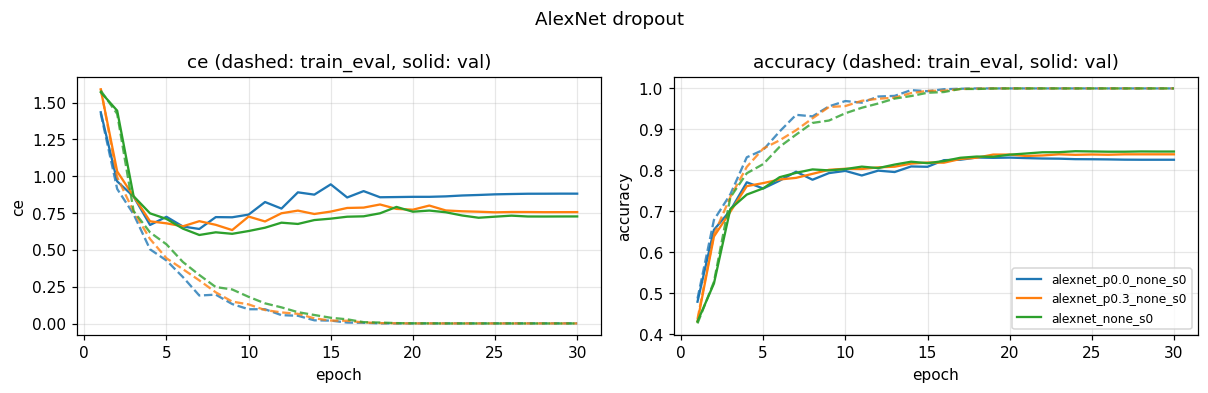

AlexNet L2


,params (M),best epoch,train acc @best,val acc (best),s / epoch,peak mem (MB),gap,min val ce,epoch of min val ce,last val ce,sum ||W||^2
run,,,,,,,,,,,
alexnet_wd0.0_none_s0,6.9768,25,1.0000,0.8304,3.4585,419.6494,0.1696,0.6270,7,1.2778,7217.3487
alexnet_none_s0,6.9768,24,1.0000,0.8468,3.6659,417.5557,0.1532,0.6011,7,0.7270,1424.5234
alexnet_wd0.005_none_s0,6.9768,28,0.9632,0.8432,3.7139,419.6182,0.1200,0.4751,29,0.4768,196.3166


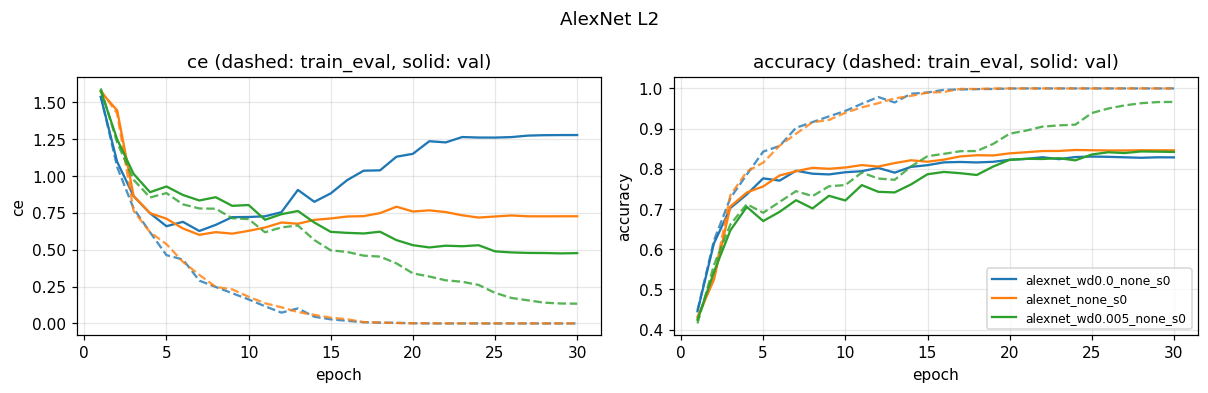

AlexNet no regularisation


,params (M),best epoch,train acc @best,val acc (best),s / epoch,peak mem (MB),gap,min val ce,epoch of min val ce,last val ce,sum ||W||^2
run,,,,,,,,,,,
alexnet_noreg_none_s0,6.9768,28,1.0,0.8122,3.4908,418.8994,0.1878,0.6933,5,1.5863,6094.4479
alexnet_none_s0,6.9768,24,1.0,0.8468,3.6659,417.5557,0.1532,0.6011,7,0.7270,1424.5234


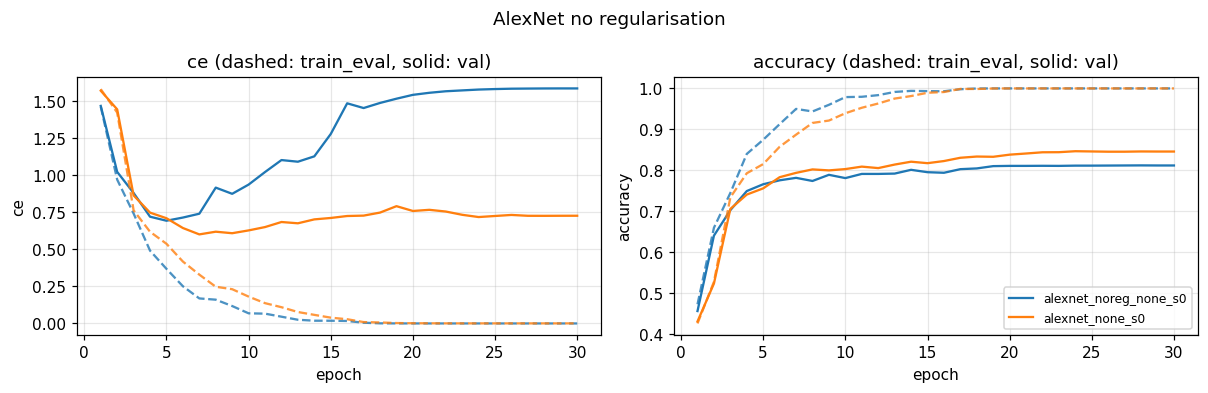

ResNet depth and width


,params (M),best epoch,train acc @best,val acc (best),s / epoch,peak mem (MB),gap,min val ce,epoch of min val ce,last val ce,sum ||W||^2
run,,,,,,,,,,,
resnet10_none_s0,4.9032,29,1.0,0.8834,5.7777,606.3687,0.1166,0.4363,29,0.4371,826.5905
resnet18_w0.5_none_s0,2.7976,27,1.0,0.8780,4.2789,385.0078,0.1220,0.4676,29,0.4709,993.5428
resnet18_none_s0,11.1740,29,1.0,0.8922,11.2806,828.3062,0.1078,0.4571,29,0.4608,1005.3111


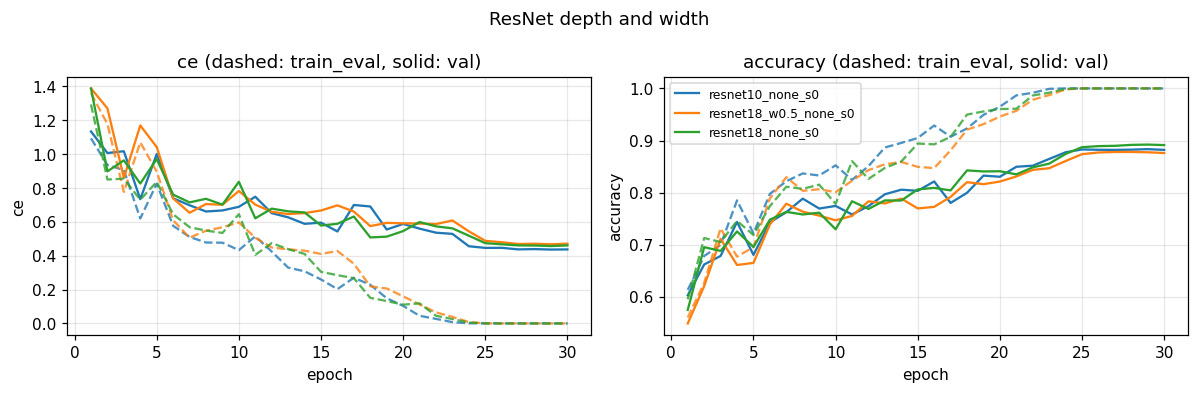

In [17]:
def weight_sq_norm(model):
    return sum(p.detach().float().pow(2).sum().item() for p in model.net.parameters() if p.ndim > 1)


def task3_table(cfgs):
    names = [c.name for c in cfgs]
    t = summary_table(names)[["params (M)", "best epoch", "train acc @best", "val acc (best)", "s / epoch", "peak mem (MB)"]]
    t["gap"] = t["train acc @best"] - t["val acc (best)"]
    t["min val ce"] = [RUNS[n].history.val_ce.min() for n in names]
    t["epoch of min val ce"] = [int(RUNS[n].history.val_ce.idxmin()) + 1 for n in names]
    t["last val ce"] = [RUNS[n].history.val_ce.iloc[-1] for n in names]
    t["sum ||W||^2"] = [weight_sq_norm(RUNS[n].model) for n in names]
    return t


print("noise level (std of best val acc over 3 seeds):")
display(seed_stats["val acc (best)"])
for group, cfgs in task3_groups.items():
    print(group)
    display(task3_table(cfgs))
    plot_curves([c.name for c in cfgs], group)

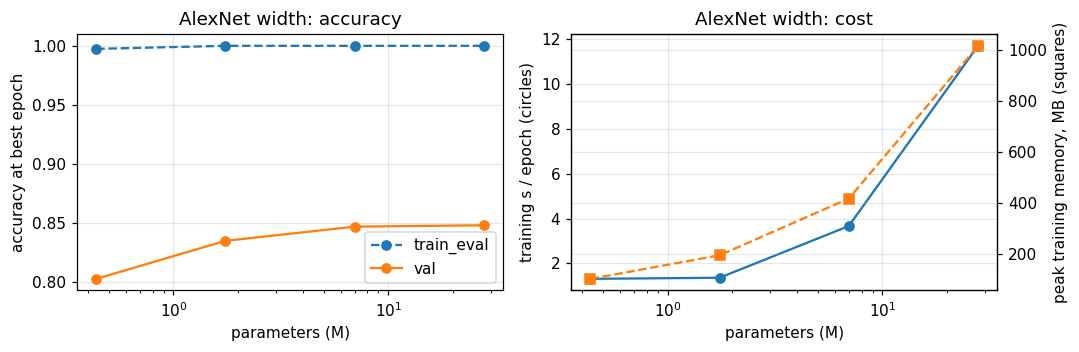

In [18]:
wt = task3_table(task3_groups["AlexNet width"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(wt["params (M)"], wt["train acc @best"], "o--", label="train_eval")
axes[0].plot(wt["params (M)"], wt["val acc (best)"], "o-", label="val")
axes[0].set(xscale="log", xlabel="parameters (M)", ylabel="accuracy at best epoch", title="AlexNet width: accuracy")
axes[0].legend()
axes[1].plot(wt["params (M)"], wt["s / epoch"], "o-", label="s / epoch")
ax2 = axes[1].twinx()
ax2.plot(wt["params (M)"], wt["peak mem (MB)"], "s--", color="C1")
axes[1].set(xscale="log", xlabel="parameters (M)", ylabel="training s / epoch (circles)", title="AlexNet width: cost")
ax2.set_ylabel("peak training memory, MB (squares)")
fig.tight_layout()
plt.show()

## Task 4. Evaluate Robustness
### 4.1 Training augmentations
Augmentations are random training views, drawn per image and per epoch from the run's generator, and applied on the GPU after the uint8 to float conversion:
* `cropflip`: pad 4 pixels with zeros, random 32x32 crop, horizontal flip with p = 0.5. Both are label-preserving for all ten classes (no class depends on left/right orientation) and model small changes of framing.
* `strong`: `cropflip`, then a random affine warp (rotation ±20°, shear ±10° on each axis, scale 0.9-1.1) and, for half of the images, Gaussian noise with σ ~ U(0, 0.06). It overlaps with part of the evaluation corruptions below (moderate rotation, shear and noise) but not with blur and not with the strongest levels, so I can see whether augmentation helps only inside the range it covers.

Each condition is trained with the Task 2 settings (30 epochs, same learning rates) and three seeds.

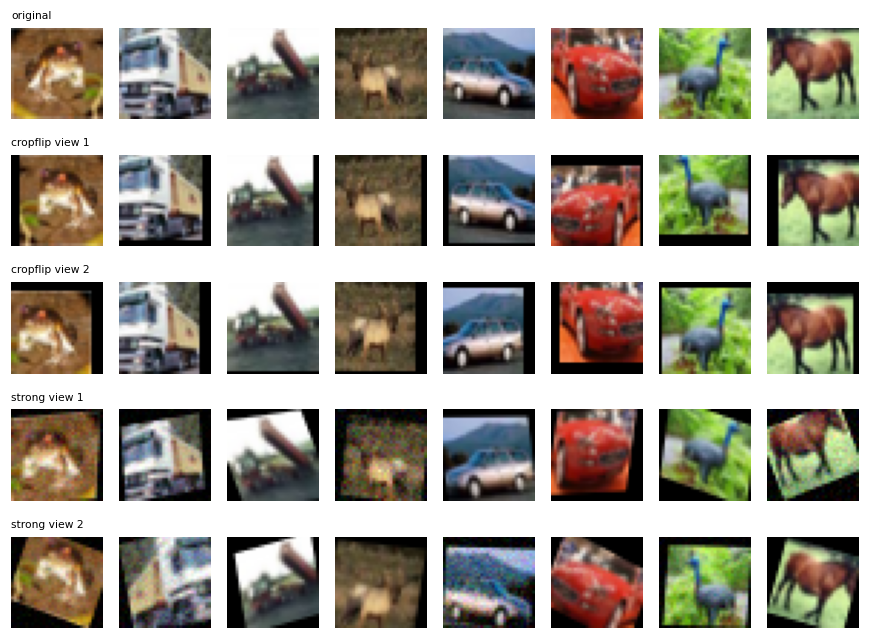

In [19]:
def random_crop_flip(x, gen, pad=4):
    B, C, H, W = x.shape
    padded = F.pad(x, (pad, pad, pad, pad))
    dy = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=gen)
    dx = torch.randint(0, 2 * pad + 1, (B,), device=x.device, generator=gen)
    rows = (dy[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (dx[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    out = padded[torch.arange(B, device=x.device)[:, None, None, None],
                 torch.arange(C, device=x.device)[None, :, None, None], rows, cols]
    flip = torch.rand(B, device=x.device, generator=gen) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.contiguous(memory_format=torch.channels_last)


def affine_warp(x, angle_deg, shear_deg=None, scale=None):
    """Per-image rotation / shear / scaling around the image centre, zero fill outside the image."""
    B = x.shape[0]
    a = torch.deg2rad(angle_deg)
    M = torch.stack([torch.stack([torch.cos(a), -torch.sin(a)], -1),
                     torch.stack([torch.sin(a), torch.cos(a)], -1)], -2)
    if shear_deg is not None:
        s = torch.tan(torch.deg2rad(shear_deg))
        one = torch.ones_like(s[:, 0])
        M = M @ torch.stack([torch.stack([one, s[:, 0]], -1), torch.stack([s[:, 1], one], -1)], -2)
    if scale is not None:
        M = M / scale[:, None, None]   # the grid maps output to input coordinates
    theta = torch.cat([M, torch.zeros(B, 2, 1, device=x.device)], 2)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x.contiguous(), grid, mode="bilinear", padding_mode="zeros", align_corners=False)


def uniform(lo, hi, shape, gen):
    return lo + (hi - lo) * torch.rand(shape, device=device, generator=gen)


def strong_augment(x, gen):
    x = random_crop_flip(x, gen)
    B = len(x)
    x = affine_warp(x, uniform(-20, 20, (B,), gen), uniform(-10, 10, (B, 2), gen), uniform(0.9, 1.1, (B,), gen))
    sigma = uniform(0, 0.06, (B,), gen) * (torch.rand(B, device=device, generator=gen) < 0.5)
    x = x + sigma[:, None, None, None] * torch.randn(x.shape, device=device, generator=gen)
    return x.clamp(0, 1).contiguous(memory_format=torch.channels_last)


AUGMENTATIONS.update({"cropflip": random_crop_flip, "strong": strong_augment})

g = torch.Generator(device=device).manual_seed(0)
views = splits["train"].x[:8]
view_rows = [("original", to_float(views))] + [(f"{a} view {k}", AUGMENTATIONS[a](to_float(views), g))
                                               for a in ("cropflip", "strong") for k in (1, 2)]
fig, axes = plt.subplots(len(view_rows), 8, figsize=(8, 1.2 * len(view_rows)))
for r, (label, batch) in enumerate(view_rows):
    for k in range(8):
        axes[r, k].imshow(batch[k].float().permute(1, 2, 0).cpu().clamp(0, 1))
        axes[r, k].axis("off")
    axes[r, 0].set_title(label, fontsize=7, loc="left")
fig.tight_layout()
plt.show()

[alexnet_cropflip_s0] loaded from cache: best val acc 0.8978 (epoch 28)
[resnet18_cropflip_s0] loaded from cache: best val acc 0.9334 (epoch 29)
[alexnet_cropflip_s1] loaded from cache: best val acc 0.8942 (epoch 29)
[resnet18_cropflip_s1] loaded from cache: best val acc 0.9388 (epoch 30)
[alexnet_cropflip_s2] loaded from cache: best val acc 0.8952 (epoch 30)
[resnet18_cropflip_s2] loaded from cache: best val acc 0.9342 (epoch 30)
[alexnet_strong_s0] loaded from cache: best val acc 0.8734 (epoch 30)
[resnet18_strong_s0] loaded from cache: best val acc 0.9110 (epoch 30)
[alexnet_strong_s1] loaded from cache: best val acc 0.8776 (epoch 27)
[resnet18_strong_s1] loaded from cache: best val acc 0.9152 (epoch 28)
[alexnet_strong_s2] loaded from cache: best val acc 0.8720 (epoch 28)
[resnet18_strong_s2] loaded from cache: best val acc 0.9148 (epoch 29)


val acc (best)         best epoch         train acc @best  \
                            mean     std       mean     std            mean   
arch     augment                                                              
alexnet  cropflip         0.8957  0.0019    29.0000  1.0000          0.9791   
         none             0.8461  0.0058    28.0000  3.4641          1.0000   
         strong           0.8743  0.0029    28.3333  1.5275          0.9327   
resnet18 cropflip         0.9355  0.0029    29.6667  0.5774          0.9919   
         none             0.8899  0.0046    27.6667  1.5275          1.0000   
         strong           0.9137  0.0023    29.0000  1.0000          0.9537   

                          s / epoch          
                      std      mean     std  
arch     augment                             
alexnet  cropflip  0.0028    3.8344  0.0351  
         none      0.0000    3.6677  0.0062  
         strong    0.0027    4.0598  0.0416  
resnet18 cropflip  0.0008   11.4531  0.0235  
         none      0.0000   11.2867  0.0055  
         strong    0.0002   11.6840  0.0131

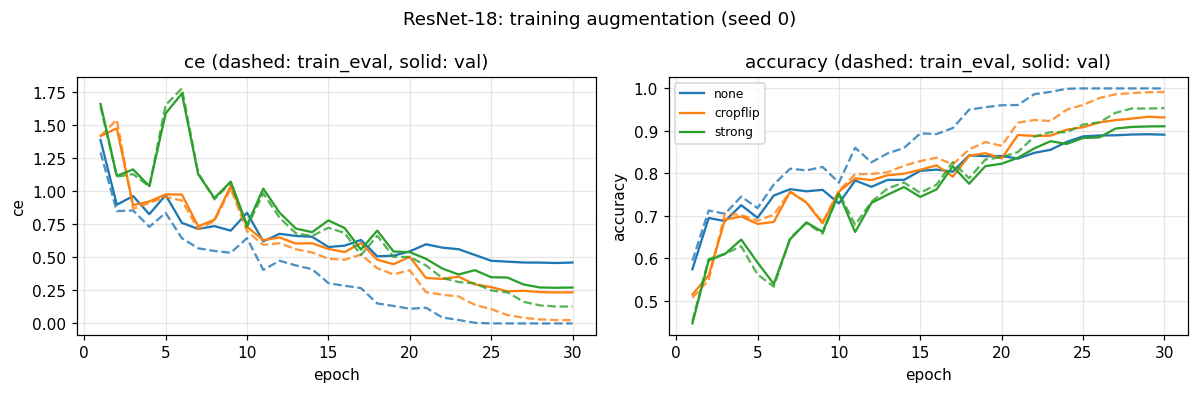

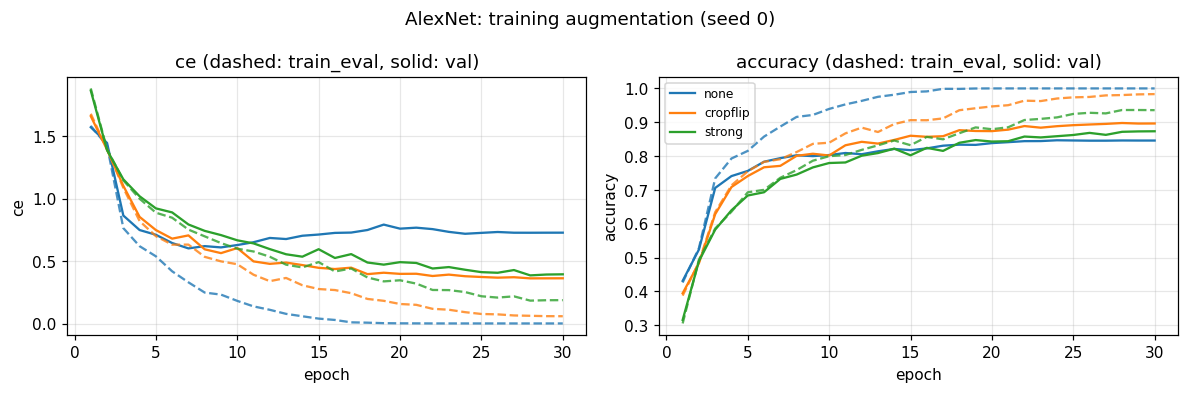

In [20]:
AUG_CONDITIONS = ["none", "cropflip", "strong"]
for aug in ["cropflip", "strong"]:
    for seed in SEEDS:
        train_run(baseline_cfg("alexnet", seed, augment=aug))
        train_run(baseline_cfg("resnet18", seed, augment=aug))

aug_names = [f"{a}_{aug}_s{s}" for a in ["alexnet", "resnet18"] for aug in AUG_CONDITIONS for s in SEEDS]
t4_train = summary_table(aug_names)
t4_train["arch"] = [n.split("_")[0] for n in t4_train.index]
t4_train["augment"] = [n.split("_")[1] for n in t4_train.index]
display(t4_train.groupby(["arch", "augment"])[["val acc (best)", "best epoch", "train acc @best", "s / epoch"]]
        .agg(["mean", "std"]))
plot_curves([f"resnet18_{aug}_s0" for aug in AUG_CONDITIONS], "ResNet-18: training augmentation (seed 0)", AUG_CONDITIONS)
plot_curves([f"alexnet_{aug}_s0" for aug in AUG_CONDITIONS], "AlexNet: training augmentation (seed 0)", AUG_CONDITIONS)

### 4.2 Reproducible corrupted evaluation sets
Four corruption families with three severities each. Every corrupted set is generated once from fixed images with a fixed seed (2223 + offset per family and level), rounded back to uint8 as if it were stored as an image, and reused for every model. The levels were checked on the validation images (4.3) and then frozen; the same function is applied to the test images for the final comparison (4.4).

| family | parameter | levels |
|---|---|---|
| rotation | angle, random sign per image, zero fill | 15°, 30°, 45° |
| shear (geometric distortion) | shear angle on both axes, random signs | 10°, 20°, 30° |
| Gaussian noise | std in [0, 1] pixel units, clipped | 0.04, 0.08, 0.12 |
| Gaussian blur | std in pixels (kernel 2⌈3σ⌉+1) | 0.75, 1.25, 1.75 |

built 12 corrupted test sets (10,000 images each) and 12 validation sets (5,000 each) in 0.74 s


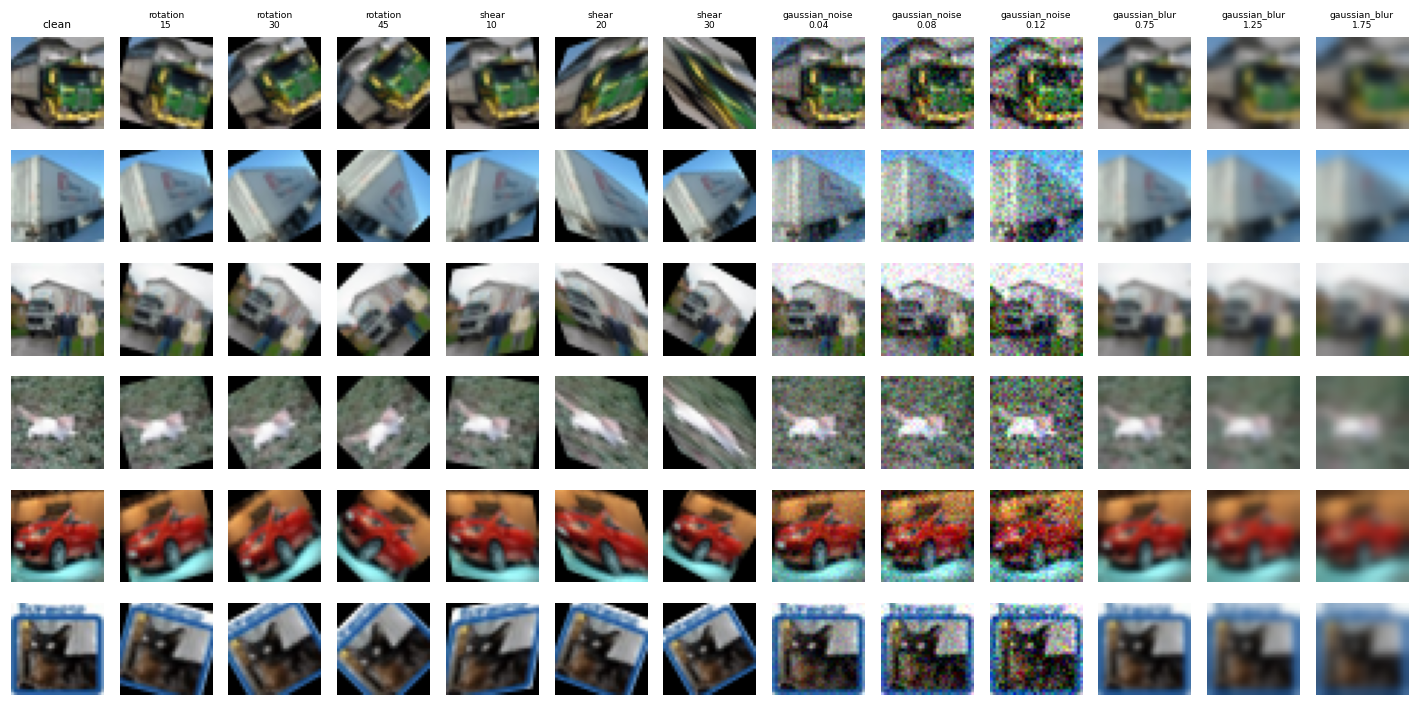

In [21]:
CORRUPTIONS = {
    "rotation": [15, 30, 45],
    "shear": [10, 20, 30],
    "gaussian_noise": [0.04, 0.08, 0.12],
    "gaussian_blur": [0.75, 1.25, 1.75],
}


def corrupt(x_uint8, family, level, seed):
    g = torch.Generator(device=device).manual_seed(seed)
    x = x_uint8.float() / 255
    B = len(x)

    def signs(*shape):
        return torch.randint(0, 2, shape, device=device, generator=g).float() * 2 - 1

    if family == "rotation":
        out = affine_warp(x, level * signs(B))
    elif family == "shear":
        out = affine_warp(x, torch.zeros(B, device=device), level * signs(B, 2))
    elif family == "gaussian_noise":
        out = x + level * torch.randn(x.shape, device=device, generator=g)
    elif family == "gaussian_blur":
        k = 2 * math.ceil(3 * level) + 1
        out = TF.gaussian_blur(x, [k, k], [level, level])
    else:
        raise ValueError(family)
    return (out.clamp(0, 1) * 255).round().to(torch.uint8)


def build_corrupted(split, families=CORRUPTIONS, seed_base=2223):
    sets = {}
    for f_idx, (family, levels) in enumerate(families.items()):
        for l_idx, level in enumerate(levels):
            sets[(family, level)] = corrupt(splits[split].x, family, level, seed=seed_base + 100 * f_idx + l_idx)
    return sets


synchronize(); t0 = time.perf_counter()
corrupted = {"val": build_corrupted("val"), "test": build_corrupted("test")}
synchronize()
corruption_build_seconds = time.perf_counter() - t0
print(f"built {len(corrupted['test'])} corrupted test sets (10,000 images each) and "
      f"{len(corrupted['val'])} validation sets (5,000 each) in {corruption_build_seconds:.2f} s")

fig, axes = plt.subplots(6, 13, figsize=(13, 6.6))
for r in range(6):
    axes[r, 0].imshow(splits["val"].x[r].permute(1, 2, 0).cpu())
    for c, key in enumerate(corrupted["val"]):
        axes[r, c + 1].imshow(corrupted["val"][key][r].permute(1, 2, 0).cpu())
        if r == 0:
            axes[r, c + 1].set_title(f"{key[0]}\n{key[1]}", fontsize=6)
axes[0, 0].set_title("clean", fontsize=7)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()

### 4.3 Development check on validation images
Seed-0 models on the validation corruptions. The levels should give a graded drop for every family without making the images unrecognisable.

In [22]:
def robustness_table(names, split, sets=None):
    sets = corrupted[split] if sets is None else sets
    rows = []
    y = splits[split].y
    for n in names:
        model = RUNS[n].model
        row = {"run": n, "clean": evaluate(model, splits[split].x, y)["accuracy"]}
        for key, xc in sets.items():
            row[key] = evaluate(model, xc, y)["accuracy"]
        rows.append(row)
    t = pd.DataFrame(rows).set_index("run")
    t.columns = pd.MultiIndex.from_tuples([("clean", "")] + list(sets.keys()))
    t[("mean corrupted", "")] = t.drop(columns=[("clean", "")]).mean(axis=1)
    return t


display(robustness_table([f"{a}_{aug}_s0" for a in ["alexnet", "resnet18"] for aug in AUG_CONDITIONS], "val"))

clean rotation                   shear                  \
                                   15      30      45      10      20      30   
run                                                                             
alexnet_none_s0       0.8468   0.6290  0.3580  0.2526  0.6942  0.4676  0.2754   
alexnet_cropflip_s0   0.8978   0.7864  0.4826  0.3246  0.8138  0.5654  0.3342   
alexnet_strong_s0     0.8734   0.8670  0.7896  0.5890  0.8708  0.8060  0.6180   
resnet18_none_s0      0.8922   0.6958  0.4240  0.3208  0.7568  0.5004  0.3020   
resnet18_cropflip_s0  0.9334   0.8120  0.4840  0.3684  0.8502  0.5806  0.3444   
resnet18_strong_s0    0.9110   0.9078  0.8488  0.6546  0.9148  0.8578  0.6422   

                     gaussian_noise                 gaussian_blur          \
                               0.04    0.08    0.12          0.75    1.25   
run                                                                         
alexnet_none_s0              0.8234  0.7104  0.5692        0.6990  0.4072   
alexnet_cropflip_s0          0.8554  0.6512  0.4238        0.7242  0.4000   
alexnet_strong_s0            0.8596  0.8080  0.6734        0.8328  0.6306   
resnet18_none_s0             0.7452  0.4286  0.2386        0.6300  0.2294   
resnet18_cropflip_s0         0.7546  0.3840  0.2022        0.5576  0.2002   
resnet18_strong_s0           0.8992  0.8372  0.7032        0.8828  0.5128   

                             mean corrupted  
                        1.75                 
run                                          
alexnet_none_s0       0.2764         0.5135  
alexnet_cropflip_s0   0.2798         0.5534  
alexnet_strong_s0     0.4412         0.7322  
resnet18_none_s0      0.1800         0.4543  
resnet18_cropflip_s0  0.1696         0.4756  
resnet18_strong_s0    0.2990         0.7467

### 4.4 Final comparison on the test images
All 18 models (2 architectures × 3 training conditions × 3 seeds) on the clean test set and the 12 frozen test corruptions. Mean and standard deviation are over seeds.

In [23]:
synchronize(); t0 = time.perf_counter()
rob_test = robustness_table(aug_names, "test")
synchronize()
robust_eval_seconds = (time.perf_counter() - t0) / len(aug_names)
groups = [pd.Index([n.split("_")[0] for n in rob_test.index], name="arch"),
          pd.Index([n.split("_")[1] for n in rob_test.index], name="augment")]
rob_mean = rob_test.groupby(groups).mean()
rob_std = rob_test.groupby(groups).std()
family_mean = pd.DataFrame({fam: rob_test[[(fam, l) for l in lv]].mean(axis=1) for fam, lv in CORRUPTIONS.items()})
family_mean["arch"], family_mean["augment"] = groups[0].values, groups[1].values
print("test accuracy, mean over 3 seeds")
display(rob_mean)
print("std over seeds")
display(rob_std[[("clean", ""), ("mean corrupted", "")]])
print("mean accuracy per family (over the three levels), mean and std over seeds")
display(family_mean.groupby(["arch", "augment"]).agg(["mean", "std"]))
print(f"evaluation cost: {robust_eval_seconds:.2f} s per model for the clean + 12 corrupted test sets (130,000 images)")

test accuracy, mean over 3 seeds


clean rotation                   shear                  \
                                15      30      45      10      20      30   
arch     augment                                                             
alexnet  cropflip  0.8922   0.7808  0.4722  0.3128  0.8182  0.5730  0.3229   
         none      0.8407   0.6251  0.3612  0.2505  0.6907  0.4717  0.2769   
         strong    0.8735   0.8617  0.7860  0.5765  0.8675  0.8105  0.6227   
resnet18 cropflip  0.9320   0.8112  0.5069  0.3601  0.8517  0.5973  0.3550   
         none      0.8810   0.7077  0.4245  0.3137  0.7641  0.5032  0.3144   
         strong    0.9131   0.9089  0.8487  0.6316  0.9098  0.8565  0.6256   

                  gaussian_noise                 gaussian_blur          \
                            0.04    0.08    0.12          0.75    1.25   
arch     augment                                                         
alexnet  cropflip         0.8459  0.6444  0.4133        0.7104  0.3987   
         none             0.8172  0.7023  0.5400        0.6899  0.4115   
         strong           0.8641  0.8097  0.6787        0.8312  0.6163   
resnet18 cropflip         0.7656  0.4041  0.2116        0.5770  0.1774   
         none             0.7319  0.4435  0.2674        0.6185  0.2522   
         strong           0.8969  0.8376  0.7200        0.8805  0.5242   

                          mean corrupted  
                     1.75                 
arch     augment                          
alexnet  cropflip  0.2812         0.5478  
         none      0.2911         0.5107  
         strong    0.4230         0.7290  
resnet18 cropflip  0.1470         0.4804  
         none      0.2115         0.4627  
         strong    0.2831         0.7436

std over seeds


clean mean corrupted
                                        
arch     augment                        
alexnet  cropflip  0.0017         0.0054
         none      0.0009         0.0030
         strong    0.0017         0.0039
resnet18 cropflip  0.0022         0.0045
         none      0.0032         0.0099
         strong    0.0034         0.0031

mean accuracy per family (over the three levels), mean and std over seeds


rotation           shear         gaussian_noise          \
                      mean     std    mean     std           mean     std   
arch     augment                                                            
alexnet  cropflip   0.5219  0.0078  0.5713  0.0043         0.6345  0.0083   
         none       0.4123  0.0060  0.4797  0.0020         0.6865  0.0149   
         strong     0.7414  0.0047  0.7669  0.0003         0.7842  0.0039   
resnet18 cropflip   0.5594  0.0081  0.6013  0.0065         0.4604  0.0137   
         none       0.4820  0.0090  0.5272  0.0100         0.4809  0.0142   
         strong     0.7964  0.0067  0.7973  0.0053         0.8182  0.0090   

                  gaussian_blur          
                           mean     std  
arch     augment                         
alexnet  cropflip        0.4634  0.0080  
         none            0.4642  0.0057  
         strong          0.6235  0.0104  
resnet18 cropflip        0.3005  0.0099  
         none            0.3608  0.0203  
         strong          0.5626  0.0167

evaluation cost: 6.59 s per model for the clean + 12 corrupted test sets (130,000 images)


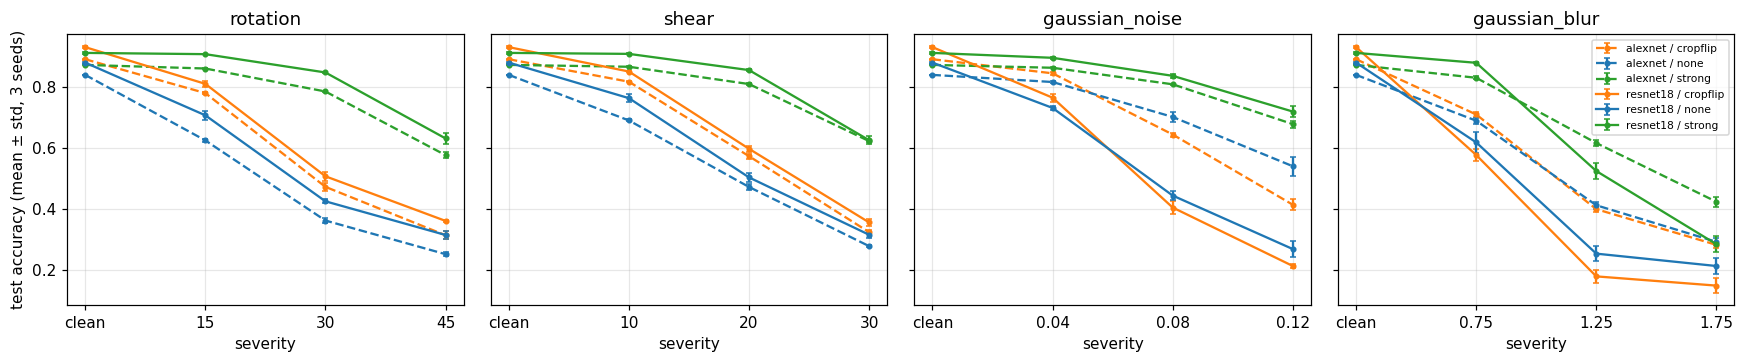

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, (family, levels) in zip(axes, CORRUPTIONS.items()):
    for arch, aug in rob_mean.index:
        means = [rob_mean.loc[(arch, aug), ("clean", "")]] + [rob_mean.loc[(arch, aug), (family, l)] for l in levels]
        stds = [rob_std.loc[(arch, aug), ("clean", "")]] + [rob_std.loc[(arch, aug), (family, l)] for l in levels]
        style = "-" if arch == "resnet18" else "--"
        ax.errorbar(range(4), means, yerr=stds, fmt=style + "o", ms=3, capsize=2,
                    color=f"C{AUG_CONDITIONS.index(aug)}", label=f"{arch} / {aug}")
    ax.set_xticks(range(4))
    ax.set_xticklabels(["clean"] + [str(l) for l in levels])
    ax.set(title=family, xlabel="severity")
axes[0].set_ylabel("test accuracy (mean ± std, 3 seeds)")
axes[-1].legend(fontsize=7)
fig.tight_layout()
plt.show()

### 4.5 Which errors do the corruptions introduce?
For the seed-0 ResNet-18 models at the strongest level of each family: the change in per-class recall relative to clean images, and the classes that the newly wrong predictions go to (images that are correct when clean and wrong when corrupted).

resnet18_none_s0: where the newly wrong predictions go


,newly wrong,#1,#2,#3
rotation 45,5921,cat (34%),dog (32%),bird (12%)
shear 30,6000,airplane (24%),ship (24%),cat (21%)
gaussian_noise 0.12,6596,frog (68%),bird (23%),cat (4%)
gaussian_blur 1.75,7278,cat (63%),airplane (32%),frog (3%)


resnet18_cropflip_s0: where the newly wrong predictions go


,newly wrong,#1,#2,#3
rotation 45,5865,bird (37%),cat (28%),frog (9%)
shear 30,5949,ship (26%),bird (20%),automobile (19%)
gaussian_noise 0.12,7373,frog (52%),bird (40%),deer (4%)
gaussian_blur 1.75,7715,airplane (39%),bird (30%),cat (26%)


resnet18_strong_s0: where the newly wrong predictions go


,newly wrong,#1,#2,#3
rotation 45,2868,bird (18%),cat (17%),frog (15%)
shear 30,2912,airplane (33%),ship (19%),automobile (13%)
gaussian_noise 0.12,2288,frog (40%),truck (17%),airplane (11%)
gaussian_blur 1.75,6372,cat (50%),airplane (21%),bird (11%)


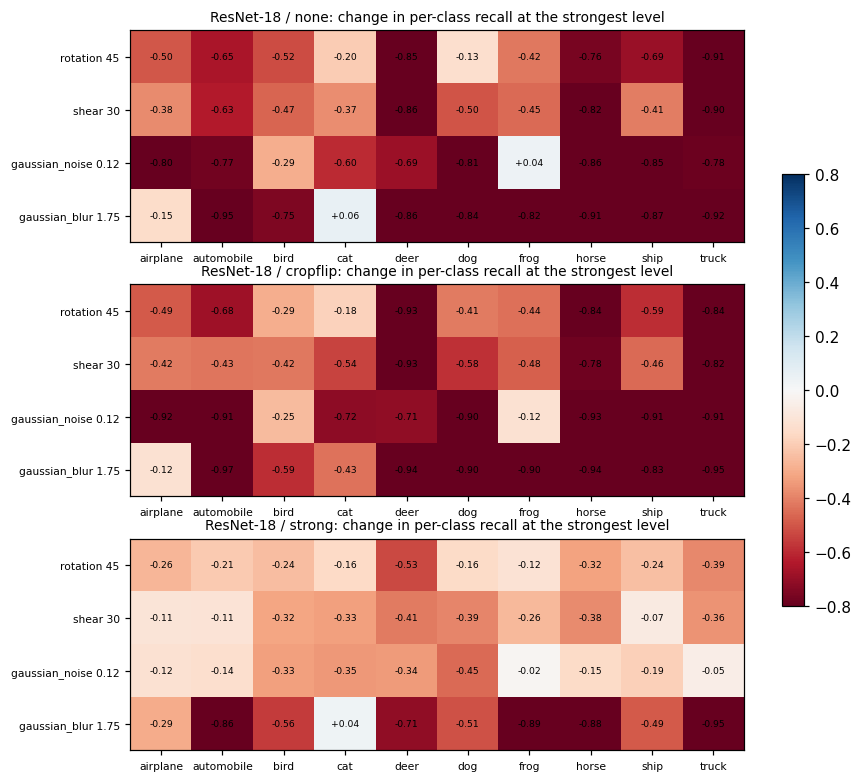

In [25]:
def corruption_error_analysis(name, split="test"):
    y = splits[split].y.cpu().numpy()
    clean_pred = evaluate(RUNS[name].model, splits[split].x, splits[split].y)["pred"].cpu().numpy()
    clean_recall = np.array([(clean_pred[y == c] == c).mean() for c in range(10)])
    drops, sinks = {}, {}
    for family, levels in CORRUPTIONS.items():
        pred = evaluate(RUNS[name].model, corrupted[split][(family, levels[-1])], splits[split].y)["pred"].cpu().numpy()
        drops[f"{family} {levels[-1]}"] = np.array([(pred[y == c] == c).mean() for c in range(10)]) - clean_recall
        flipped = (clean_pred == y) & (pred != y)
        counts = np.bincount(pred[flipped], minlength=10)
        top = counts.argsort()[::-1][:3]
        sinks[f"{family} {levels[-1]}"] = {"newly wrong": int(counts.sum()),
                                           **{f"#{k + 1}": f"{class_names[c]} ({counts[c] / counts.sum():.0%})"
                                              for k, c in enumerate(top)}}
    return pd.DataFrame(drops, index=class_names).T, pd.DataFrame(sinks).T


fig, axes = plt.subplots(3, 1, figsize=(9, 8.5))
for ax, aug in zip(axes, AUG_CONDITIONS):
    drops, sinks = corruption_error_analysis(f"resnet18_{aug}_s0")
    ax.grid(False)
    im = ax.imshow(drops.values, cmap="RdBu", vmin=-0.8, vmax=0.8, aspect="auto")
    ax.set_xticks(range(10)); ax.set_xticklabels(class_names, fontsize=7)
    ax.set_yticks(range(len(drops))); ax.set_yticklabels(drops.index, fontsize=7)
    for (i, j), v in np.ndenumerate(drops.values):
        ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"ResNet-18 / {aug}: change in per-class recall at the strongest level", fontsize=9)
    print(f"resnet18_{aug}_s0: where the newly wrong predictions go")
    display(sinks)
with plt.rc_context({"axes.grid": False}):
    fig.colorbar(im, ax=axes, shrink=0.6)
plt.show()

### 4.6 Cost and label ambiguity
The training cost of an augmentation is the change in seconds per epoch (same GPU, same number of steps). The evaluation cost is generating the corrupted sets once plus evaluating each model on them.

Transformations stronger than the ones above can remove the information that defines the label. The figure applies extreme settings to the same test images: rotation by 90° and 180°, noise σ = 0.3, blur σ = 3, and a crop that keeps only a 16x16 quarter of the image.

augment,cropflip,none,strong,cropflip overhead,strong overhead
arch,,,,,
alexnet,3.8344,3.6677,4.0598,0.0454,0.1069
resnet18,11.4531,11.2867,11.6840,0.0147,0.0352


corrupted sets: 0.74 s once; evaluation: 6.59 s per model


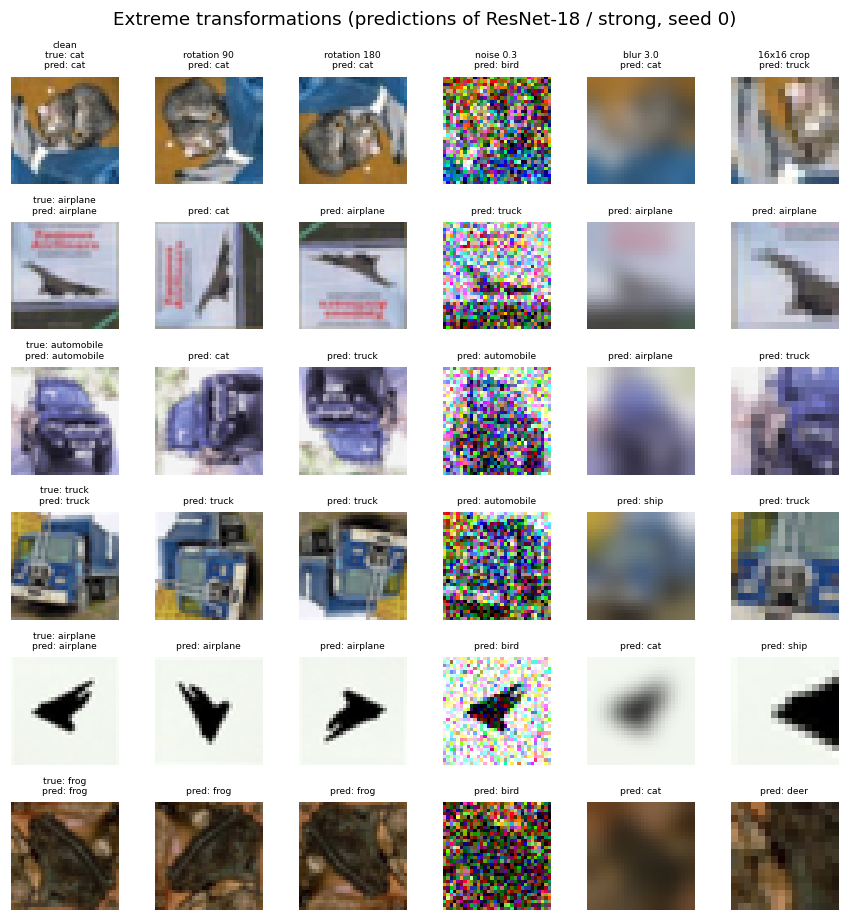

In [26]:
cost = t4_train.groupby(["arch", "augment"])["s / epoch"].mean().unstack()
cost["cropflip overhead"] = cost["cropflip"] / cost["none"] - 1
cost["strong overhead"] = cost["strong"] / cost["none"] - 1
display(cost)
print(f"corrupted sets: {corruption_build_seconds:.2f} s once; evaluation: {robust_eval_seconds:.2f} s per model")

extreme = [
    ("rotation 90", lambda x, g: affine_warp(x, torch.full((len(x),), 90.0, device=device))),
    ("rotation 180", lambda x, g: affine_warp(x, torch.full((len(x),), 180.0, device=device))),
    ("noise 0.3", lambda x, g: x + 0.3 * torch.randn(x.shape, device=device, generator=g)),
    ("blur 3.0", lambda x, g: TF.gaussian_blur(x, [19, 19], [3.0, 3.0])),
    ("16x16 crop", lambda x, g: F.interpolate(x[:, :, 8:24, :16], size=(32, 32), mode="nearest")),
]
picks = torch.tensor([0, 3, 9, 14, 21, 30], device=device)
xs = splits["test"].x[picks].float() / 255
true_names = [class_names[int(splits["test"].y[i])] for i in picks.tolist()]
g = torch.Generator(device=device).manual_seed(1)
pred_model = RUNS["resnet18_strong_s0"].model
fig, axes = plt.subplots(len(picks), len(extreme) + 1, figsize=(8, 8.5))
for c, (label, fn) in enumerate([("clean", lambda x, g: x)] + extreme):
    xe = fn(xs, g).clamp(0, 1)
    pred = predict_logits(pred_model, xe).argmax(1).cpu()
    for r in range(len(picks)):
        axes[r, c].imshow(xe[r].permute(1, 2, 0).cpu())
        head = f"{label}\n" if r == 0 else ""
        truth = f"true: {true_names[r]}\n" if c == 0 else ""
        axes[r, c].set_title(f"{head}{truth}pred: {class_names[pred[r]]}", fontsize=6)
        axes[r, c].axis("off")
fig.suptitle("Extreme transformations (predictions of ResNet-18 / strong, seed 0)")
fig.tight_layout()
plt.show()

## Task 5. Analyse Predictions and Adversarial Examples
### 5.1 Test metrics
The six seed-0 models (AlexNet and ResNet-18, three training conditions each) are evaluated on the 10,000 test images. Besides accuracy I report macro F1 (the classes are balanced, so it mainly shows whether some class is much worse), the test negative log-likelihood and the expected calibration error (ECE, 15 equal-width confidence bins), which says whether the softmax confidence can be trusted. Seed-averaged accuracies are in 4.4.

For the detailed analysis I pick one model per architecture by **validation** accuracy, so the test set does not influence the choice.

In [27]:
from sklearn.metrics import f1_score, precision_recall_fscore_support


def calibration_bins(conf, correct, n_bins=15):
    edges = np.linspace(0, 1, n_bins + 1)
    ece, rows = 0.0, []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
            rows.append((conf[m].mean(), correct[m].mean(), m.sum()))
    return ece, np.array(rows)


main_models = [f"{a}_{aug}_s0" for a in ["alexnet", "resnet18"] for aug in AUG_CONDITIONS]
y_test_np = splits["test"].y.cpu().numpy()
test_out = {}
rows = []
for n in main_models:
    r = evaluate(RUNS[n].model, splits["test"].x, splits["test"].y)
    probs = r["logits"].softmax(1).cpu().numpy()
    pred = probs.argmax(1)
    ece, _ = calibration_bins(probs.max(1), pred == y_test_np)
    test_out[n] = {"probs": probs, "pred": pred}
    rows.append({"run": n, "val acc": RUNS[n].summary["best_val_accuracy"], "test acc": r["accuracy"],
                 "macro F1": f1_score(y_test_np, pred, average="macro"), "test NLL": r["ce"],
                 "ECE": ece, "mean confidence": probs.max(1).mean()})
t5 = pd.DataFrame(rows).set_index("run")
display(t5)

FOCUS = {arch: t5.loc[[n for n in main_models if n.startswith(arch)], "val acc"].idxmax() for arch in ["alexnet", "resnet18"]}
print("models selected by validation accuracy:", FOCUS)

,val acc,test acc,macro F1,test NLL,ECE,mean confidence
run,,,,,,
alexnet_none_s0,0.8468,0.8401,0.8396,0.7753,0.1099,0.9499
alexnet_cropflip_s0,0.8978,0.8941,0.8938,0.3814,0.0556,0.9493
alexnet_strong_s0,0.8734,0.8742,0.8728,0.4055,0.0453,0.9187
resnet18_none_s0,0.8922,0.8827,0.8826,0.4928,0.0713,0.9540
resnet18_cropflip_s0,0.9334,0.9315,0.9313,0.2403,0.0305,0.9620
resnet18_strong_s0,0.9110,0.9127,0.9119,0.2686,0.0255,0.9374


models selected by validation accuracy: {'alexnet': 'alexnet_cropflip_s0', 'resnet18': 'resnet18_cropflip_s0'}


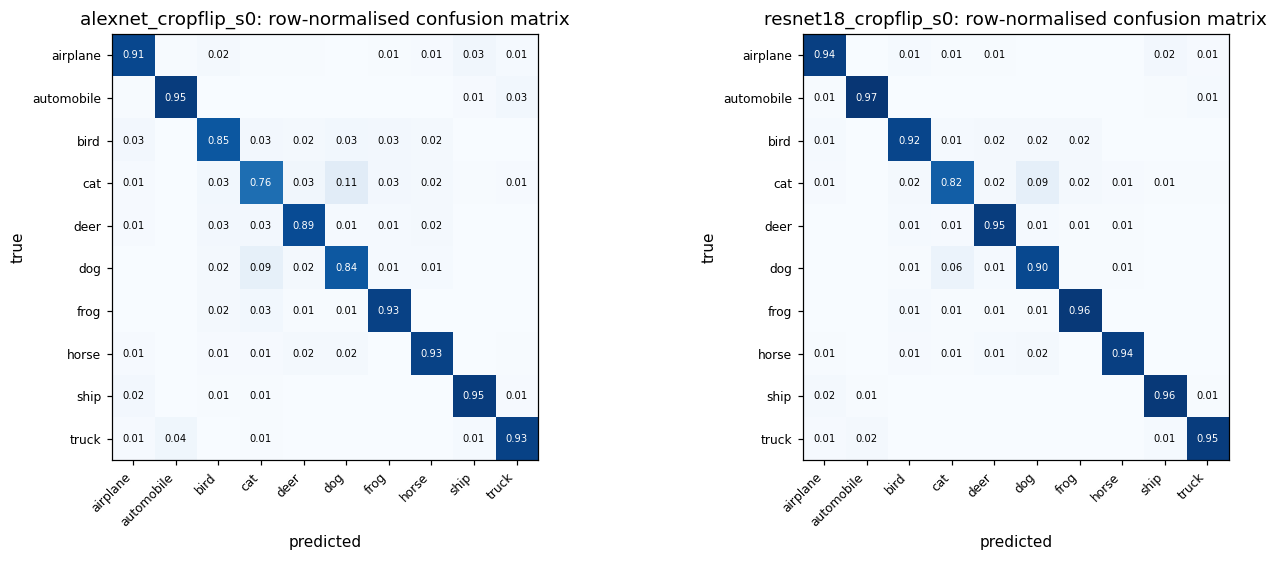

alexnet                 resnet18               
           precision recall      F1 precision recall      F1
airplane      0.9007  0.907  0.9038    0.9278  0.938  0.9329
automobile    0.9473  0.953  0.9501    0.9692  0.974  0.9716
bird          0.8706  0.848  0.8592    0.9169  0.916  0.9165
cat           0.7977  0.761  0.7789    0.8847  0.821  0.8517
deer          0.8975  0.893  0.8952    0.9268  0.949  0.9377
dog           0.8220  0.845  0.8333    0.8608  0.903  0.8814
frog          0.9127  0.930  0.9212    0.9469  0.962  0.9544
horse         0.9214  0.926  0.9237    0.9751  0.939  0.9567
ship          0.9351  0.951  0.9430    0.9496  0.961  0.9553
truck         0.9317  0.927  0.9293    0.9587  0.952  0.9553

most frequent confusions


,model,true,predicted,count
0,alexnet_cropflip_s0,cat,dog,110
1,alexnet_cropflip_s0,dog,cat,85
2,alexnet_cropflip_s0,truck,automobile,39
3,alexnet_cropflip_s0,airplane,ship,33
4,alexnet_cropflip_s0,cat,deer,32
5,alexnet_cropflip_s0,frog,cat,30
6,resnet18_cropflip_s0,cat,dog,89
7,resnet18_cropflip_s0,dog,cat,59
8,resnet18_cropflip_s0,airplane,ship,24
9,resnet18_cropflip_s0,cat,bird,22


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (arch, name) in zip(axes, FOCUS.items()):
    cm = confusion_matrix(y_test_np, test_out[name]["pred"], labels=range(10), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:.2f}" if v >= 0.005 else "", ha="center", va="center", fontsize=6.5,
                color="white" if v > 0.5 else "black")
    ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(class_names, fontsize=8)
    ax.set(xlabel="predicted", ylabel="true", title=f"{name}: row-normalised confusion matrix")
    ax.grid(False)
fig.tight_layout()
plt.show()

per_class = {}
for arch, name in FOCUS.items():
    p, r, f, _ = precision_recall_fscore_support(y_test_np, test_out[name]["pred"], labels=range(10), zero_division=0)
    per_class[(arch, "precision")], per_class[(arch, "recall")], per_class[(arch, "F1")] = p, r, f
display(pd.DataFrame(per_class, index=class_names))

pairs = []
for arch, name in FOCUS.items():
    cm = confusion_matrix(y_test_np, test_out[name]["pred"], labels=range(10))
    np.fill_diagonal(cm, 0)
    for k in np.argsort(cm, axis=None)[::-1][:6]:
        i, j = np.unravel_index(k, cm.shape)
        pairs.append({"model": name, "true": class_names[i], "predicted": class_names[j], "count": cm[i, j]})
print("most frequent confusions")
display(pd.DataFrame(pairs))

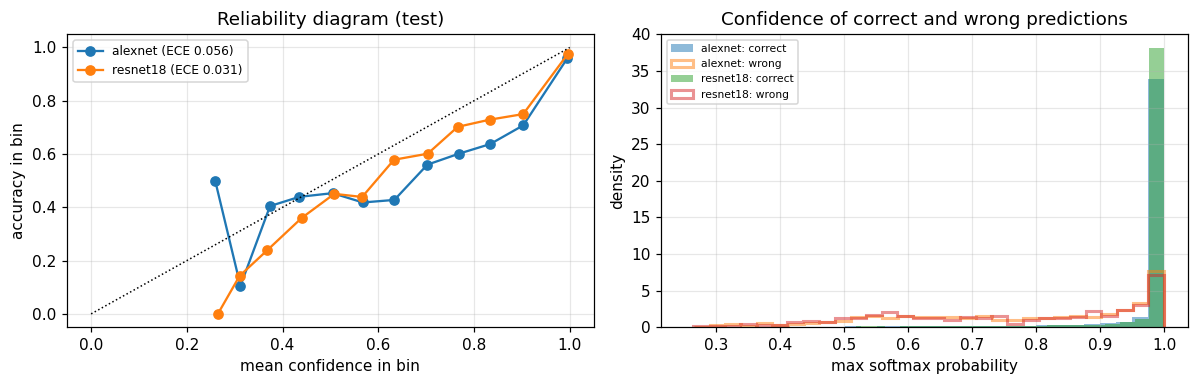

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, (arch, name) in enumerate(FOCUS.items()):
    probs, pred = test_out[name]["probs"], test_out[name]["pred"]
    conf, correct = probs.max(1), pred == y_test_np
    ece, bins = calibration_bins(conf, correct)
    axes[0].plot(bins[:, 0], bins[:, 1], "o-", label=f"{arch} (ECE {ece:.3f})")
    axes[1].hist(conf[correct], bins=30, alpha=0.5, label=f"{arch}: correct", density=True)
    axes[1].hist(conf[~correct], bins=30, alpha=0.5, label=f"{arch}: wrong", density=True, histtype="step", lw=2)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set(xlabel="mean confidence in bin", ylabel="accuracy in bin", title="Reliability diagram (test)")
axes[0].legend(fontsize=8)
axes[1].set(xlabel="max softmax probability", ylabel="density", title="Confidence of correct and wrong predictions")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

### 5.2 Training diagnostics and image characteristics
Learning curves of the two selected models, and test accuracy as a function of two simple image properties: global contrast (standard deviation of the grey-level image) and mean brightness, each split into quintiles.

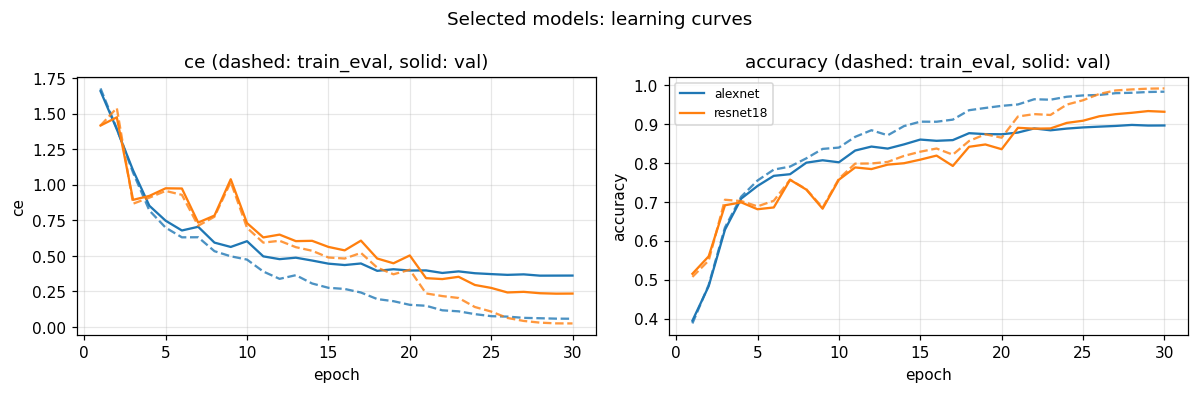

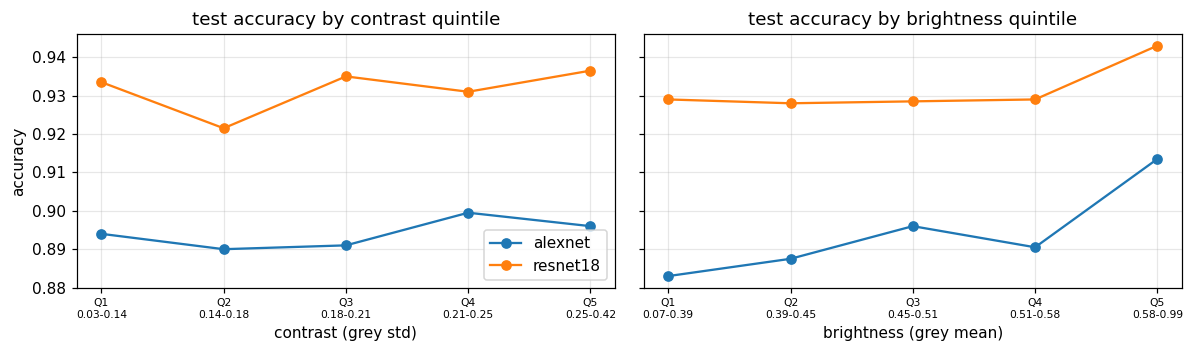

In [30]:
plot_curves(list(FOCUS.values()), "Selected models: learning curves", list(FOCUS.keys()))

grey = (X_test.astype(np.float32) / 255) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
image_props = {"contrast (grey std)": grey.std(axis=(1, 2)), "brightness (grey mean)": grey.mean(axis=(1, 2))}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, (prop, values) in zip(axes, image_props.items()):
    q = pd.qcut(values, 5, labels=False)
    for arch, name in FOCUS.items():
        correct = test_out[name]["pred"] == y_test_np
        ax.plot(range(5), [correct[q == b].mean() for b in range(5)], "o-", label=arch)
    ax.set_xticks(range(5))
    ax.set_xticklabels([f"Q{b + 1}\n{values[q == b].min():.2f}-{values[q == b].max():.2f}" for b in range(5)], fontsize=7)
    ax.set(xlabel=prop, title=f"test accuracy by {prop.split(' ')[0]} quintile")
axes[0].set_ylabel("accuracy")
axes[0].legend()
fig.tight_layout()
plt.show()

### 5.3 Examples of correct and incorrect predictions
For the selected ResNet-18: the most confident correct prediction per class, the most confident errors, and the least confident predictions (largest uncertainty).

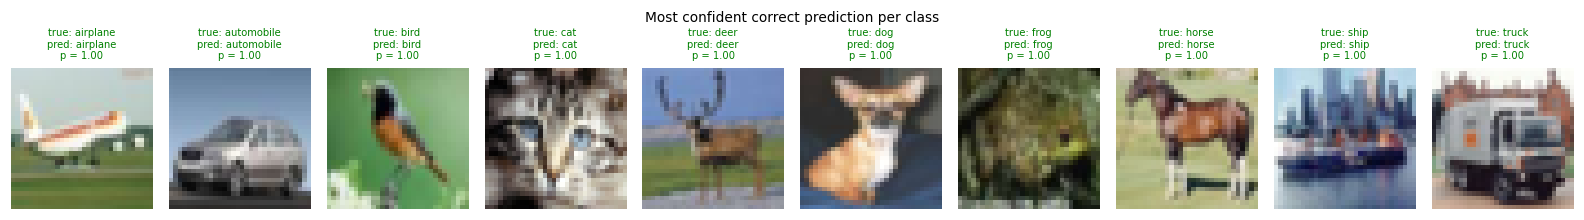

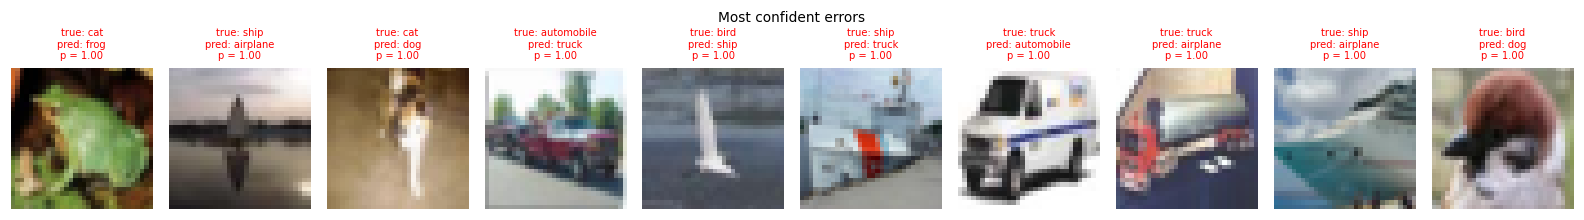

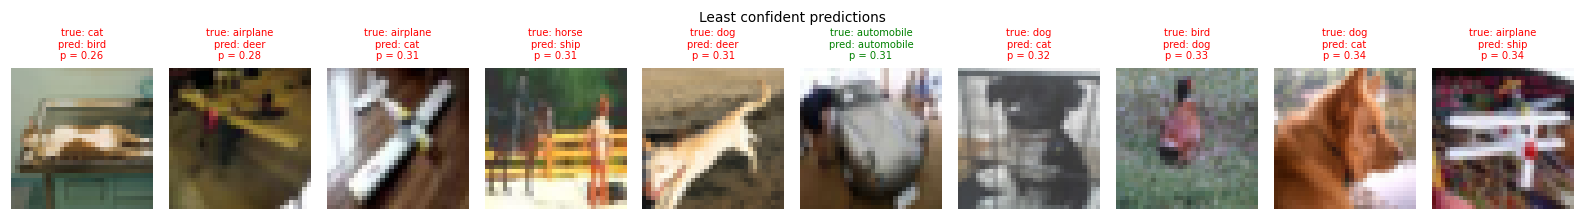

In [31]:
def show_examples(name, indices, title):
    probs, pred = test_out[name]["probs"], test_out[name]["pred"]
    fig, axes = plt.subplots(1, len(indices), figsize=(1.45 * len(indices), 2.1))
    for ax, i in zip(axes, indices):
        ax.imshow(X_test[i])
        colour = "green" if pred[i] == y_test_np[i] else "red"
        ax.set_title(f"true: {class_names[y_test_np[i]]}\npred: {class_names[pred[i]]}\np = {probs[i].max():.2f}",
                     fontsize=6.5, color=colour)
        ax.axis("off")
    fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    plt.show()


focus_res = FOCUS["resnet18"]
probs, pred = test_out[focus_res]["probs"], test_out[focus_res]["pred"]
conf = probs.max(1)
correct_idx = [int(np.flatnonzero((y_test_np == c) & (pred == c))[conf[(y_test_np == c) & (pred == c)].argmax()]) for c in range(10)]
wrong = np.flatnonzero(pred != y_test_np)
show_examples(focus_res, correct_idx, "Most confident correct prediction per class")
show_examples(focus_res, wrong[np.argsort(conf[wrong])[::-1][:10]].tolist(), "Most confident errors")
show_examples(focus_res, np.argsort(conf)[:10].tolist(), "Least confident predictions")

### 5.4 Adversarial examples
**Threat model.** White-box attacks on the trained model, with the perturbation bounded in the $L_\infty$ norm in raw pixel space: $\|x_{adv}-x\|_\infty \le \epsilon$ and $x_{adv}\in[0,1]$. I use $\epsilon \in \{0.5, 1, 2, 4, 8\}/255$; at 8-bit precision one grey level is 1/255.

**Attacks.** FGSM (one signed-gradient step of size $\epsilon$, as in Part A) and PGD (10 signed-gradient steps of size $2.5\epsilon/10$, each followed by projection back onto the $\epsilon$-ball and [0, 1]). The gradients are computed in FP32 with the model in eval mode.

**Success.** The evaluation set is the first 1,000 test images. An attack succeeds on an image if the model classifies the clean image correctly and the perturbed image incorrectly; the success rate is over the correctly classified images. As a control, the same images get a random perturbation of the same size ($\pm\epsilon$ with random sign per pixel, fixed seed), which separates sensitivity to random noise from a deliberately optimised perturbation. I also round the PGD images back to 8-bit values to see whether the attack survives storage as a normal image.

eps (x/255),0.5,1.0,2.0,4.0,8.0
model,,,,,
alexnet_none_s0,0.1189,0.2592,0.5161,0.8419,0.9715
alexnet_cropflip_s0,0.1052,0.2359,0.5526,0.9181,0.9889
alexnet_strong_s0,0.0865,0.2321,0.4937,0.8476,0.9886
resnet18_none_s0,0.3393,0.7157,0.9719,1.0000,1.0000
resnet18_cropflip_s0,0.3099,0.6954,0.9787,1.0000,1.0000
resnet18_strong_s0,0.1524,0.3708,0.7395,0.9849,1.0000


,model,eps (x/255),random success,FGSM success,PGD success,PGD 8-bit success,random acc,FGSM acc,PGD acc,seconds
0,alexnet_none_s0,0.5,0.0000,0.1106,0.1189,0.1344,0.842,0.748,0.741,1.3228
1,alexnet_none_s0,1.0,0.0012,0.2295,0.2592,0.2580,0.842,0.648,0.623,1.2783
2,alexnet_none_s0,2.0,0.0083,0.4304,0.5161,0.5161,0.838,0.479,0.407,1.2768
3,alexnet_none_s0,4.0,0.0202,0.6528,0.8419,0.8419,0.832,0.292,0.133,1.2801
4,alexnet_none_s0,8.0,0.0464,0.7824,0.9715,0.9715,0.820,0.183,0.024,1.2803
5,alexnet_cropflip_s0,0.5,0.0011,0.1019,0.1052,0.1196,0.902,0.811,0.808,1.3216
6,alexnet_cropflip_s0,1.0,0.0022,0.2016,0.2359,0.2359,0.901,0.721,0.690,1.2784
7,alexnet_cropflip_s0,2.0,0.0044,0.4197,0.5526,0.5526,0.901,0.524,0.404,1.2783
8,alexnet_cropflip_s0,4.0,0.0155,0.7043,0.9181,0.9181,0.896,0.267,0.074,1.2782
9,alexnet_cropflip_s0,8.0,0.0410,0.8859,0.9889,0.9889,0.880,0.103,0.010,1.2780


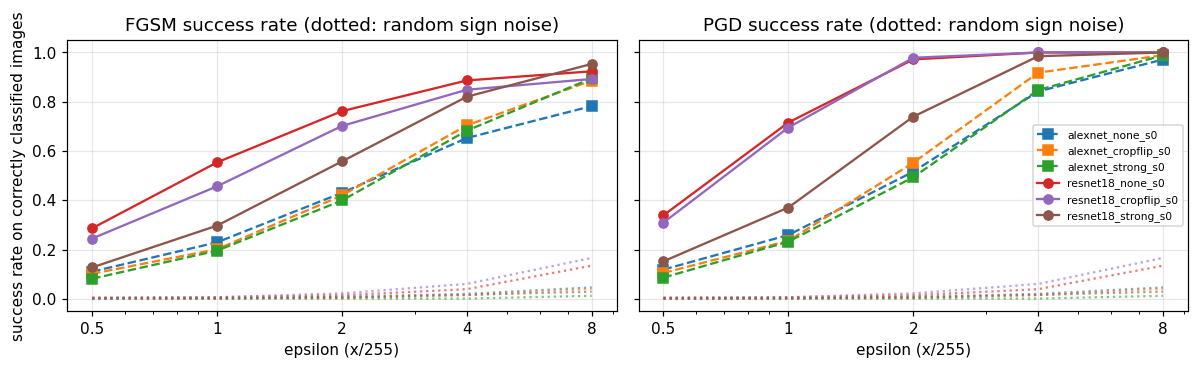

In [32]:
def fgsm(model, x, y, eps):
    x = x.clone().requires_grad_(True)
    grad, = torch.autograd.grad(F.cross_entropy(model(x), y), x)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd(model, x, y, eps, steps=10):
    alpha = 2.5 * eps / steps
    x_adv = x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()


def random_sign(x, eps, gen):
    signs = torch.randint(0, 2, x.shape, device=x.device, generator=gen).float() * 2 - 1
    return (x + eps * signs).clamp(0, 1)


@torch.no_grad()
def predict_fp32(model, x, batch_size=500):
    model.eval()
    return torch.cat([model(x[i:i + batch_size].contiguous(memory_format=torch.channels_last)).argmax(1)
                      for i in range(0, len(x), batch_size)])


EPSILONS = [0.5, 1, 2, 4, 8]
N_ATTACK = 1000
x_att = splits["test"].x[:N_ATTACK].float() / 255
y_att = splits["test"].y[:N_ATTACK]


def attack_table(name, batch_size=250):
    model = RUNS[name].model.eval()
    clean_ok = predict_fp32(model, x_att) == y_att
    rows = []
    for e in EPSILONS:
        eps = e / 255
        gen = torch.Generator(device=device).manual_seed(0)
        preds = {"random": [], "FGSM": [], "PGD": [], "PGD 8-bit": []}
        t0 = time.perf_counter()
        for i in range(0, N_ATTACK, batch_size):
            xb, yb = x_att[i:i + batch_size], y_att[i:i + batch_size]
            preds["random"].append(predict_fp32(model, random_sign(xb, eps, gen)))
            preds["FGSM"].append(predict_fp32(model, fgsm(model, xb, yb, eps)))
            x_pgd = pgd(model, xb, yb, eps)
            preds["PGD"].append(predict_fp32(model, x_pgd))
            preds["PGD 8-bit"].append(predict_fp32(model, (x_pgd * 255).round() / 255))
        synchronize()
        row = {"model": name, "eps (x/255)": e}
        for k, v in preds.items():
            wrong = torch.cat(v) != y_att
            row[f"{k} success"] = (wrong & clean_ok).sum().item() / clean_ok.sum().item()
            row[f"{k} acc"] = (~wrong).float().mean().item()
        row["seconds"] = time.perf_counter() - t0
        rows.append(row)
    return pd.DataFrame(rows)


adv = pd.concat([attack_table(n) for n in main_models], ignore_index=True)
display(adv.pivot(index="model", columns="eps (x/255)", values="PGD success").loc[main_models])
display(adv[["model", "eps (x/255)", "random success", "FGSM success", "PGD success", "PGD 8-bit success",
             "random acc", "FGSM acc", "PGD acc", "seconds"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, attack in zip(axes, ["FGSM", "PGD"]):
    for k, n in enumerate(main_models):
        d = adv[adv.model == n]
        ax.plot(d["eps (x/255)"], d[f"{attack} success"], "o-" if "resnet" in n else "s--", color=f"C{k}", label=n)
        ax.plot(d["eps (x/255)"], d["random success"], ":", color=f"C{k}", alpha=0.6)
    ax.set(xscale="log", xlabel="epsilon (x/255)", title=f"{attack} success rate (dotted: random sign noise)")
    ax.set_xticks(EPSILONS); ax.set_xticklabels([str(e) for e in EPSILONS])
axes[0].set_ylabel("success rate on correctly classified images")
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()

**One adversarial example in detail.** A test image that the selected ResNet-18 classifies correctly with high confidence, attacked with PGD at the smallest ε in the grid that changes its prediction. The perturbation is shown amplified to the full colour range.

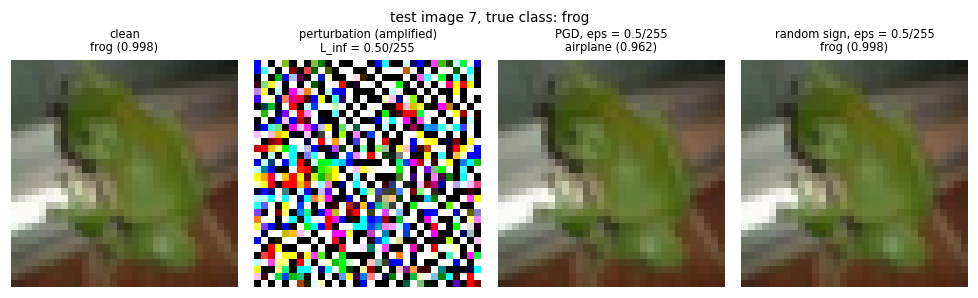

L2 norm of the perturbation: 0.101 (image L2 norm 21.1)
top-3 classes after the attack: [('airplane', 0.962), ('bird', 0.026), ('frog', 0.011)]


In [33]:
model = RUNS[focus_res].model.eval()
with torch.no_grad():
    p_clean = model(x_att.contiguous(memory_format=torch.channels_last)).softmax(1)
conf_clean, pred_clean = p_clean.max(1)
candidates = torch.nonzero((pred_clean == y_att) & (conf_clean > 0.99)).flatten()[:200]
example = None
for e in EPSILONS:
    x_adv = pgd(model, x_att[candidates], y_att[candidates], e / 255)
    flipped = torch.nonzero(predict_fp32(model, x_adv) != y_att[candidates]).flatten()
    if len(flipped):
        k = int(flipped[0])
        example = (int(candidates[k]), e, x_adv[k])
        break
if example is None:
    print("no image was flipped within the largest epsilon")
else:
    i, e, xa = example
    x0 = x_att[i]
    xr = random_sign(x0[None], e / 255, torch.Generator(device=device).manual_seed(0))[0]
    with torch.no_grad():
        probs3 = model(torch.stack([x0, xa, xr]).contiguous(memory_format=torch.channels_last)).softmax(1).cpu()
    delta = (xa - x0)
    fig, axes = plt.subplots(1, 4, figsize=(9, 2.8))
    panels = [(x0, f"clean\n{class_names[probs3[0].argmax()]} ({probs3[0].max():.3f})"),
              (0.5 + delta / (2 * delta.abs().max()), f"perturbation (amplified)\nL_inf = {delta.abs().max() * 255:.2f}/255"),
              (xa, f"PGD, eps = {e}/255\n{class_names[probs3[1].argmax()]} ({probs3[1].max():.3f})"),
              (xr, f"random sign, eps = {e}/255\n{class_names[probs3[2].argmax()]} ({probs3[2].max():.3f})")]
    for ax, (img, title) in zip(axes, panels):
        ax.imshow(img.permute(1, 2, 0).cpu().clamp(0, 1))
        ax.set_title(title, fontsize=7.5)
        ax.axis("off")
    fig.suptitle(f"test image {i}, true class: {class_names[int(y_att[i])]}", fontsize=9)
    fig.tight_layout()
    plt.show()
    print(f"L2 norm of the perturbation: {delta.norm().item():.3f} (image L2 norm {x0.norm().item():.1f})")
    top = probs3[1].topk(3)
    print("top-3 classes after the attack:", [(class_names[c], round(p.item(), 3)) for p, c in zip(top.values, top.indices)])

**Transfer between architectures.** PGD images computed against one model (ε = 4/255) are given to the other architecture trained with the same condition, which tests whether the perturbation is specific to the attacked weights.

In [34]:
transfer_rows = []
for aug in AUG_CONDITIONS:
    for src, dst in [("resnet18", "alexnet"), ("alexnet", "resnet18")]:
        s_model, d_model = RUNS[f"{src}_{aug}_s0"].model.eval(), RUNS[f"{dst}_{aug}_s0"].model.eval()
        x_adv = torch.cat([pgd(s_model, x_att[i:i + 250], y_att[i:i + 250], 4 / 255) for i in range(0, N_ATTACK, 250)])
        ok = predict_fp32(d_model, x_att) == y_att
        transfer_rows.append({"augment": aug, "source": src, "target": dst,
                              "success on target": ((predict_fp32(d_model, x_adv) != y_att) & ok).sum().item() / ok.sum().item(),
                              "white-box success on source": adv[(adv.model == f"{src}_{aug}_s0") & (adv["eps (x/255)"] == 4)]["PGD success"].item()})
display(pd.DataFrame(transfer_rows))

,augment,source,target,success on target,white-box success on source
0,none,resnet18,alexnet,0.1153,1.0000
1,none,alexnet,resnet18,0.5000,0.8419
2,cropflip,resnet18,alexnet,0.1373,1.0000
3,cropflip,alexnet,resnet18,0.5272,0.9181
4,strong,resnet18,alexnet,0.1911,0.9849
5,strong,alexnet,resnet18,0.3557,0.8476


## Task 6. Benchmark and Discuss the Tradeoffs
### 6.1 Compute per image
Multiply-accumulate operations (MACs) per 32x32 image, counted from the conv and linear layer shapes with forward hooks.

In [35]:
def count_macs(net):
    macs = []
    def conv_hook(m, i, o):
        macs.append(o.numel() // o.shape[0] * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1])
    def lin_hook(m, i, o):
        macs.append(m.in_features * m.out_features)
    hooks = [m.register_forward_hook(conv_hook) for m in net.modules() if isinstance(m, nn.Conv2d)]
    hooks += [m.register_forward_hook(lin_hook) for m in net.modules() if isinstance(m, nn.Linear)]
    net.eval()
    with torch.no_grad():
        net(torch.zeros(1, 3, 32, 32, device=next(net.parameters()).device))
    for h in hooks:
        h.remove()
    return sum(macs)


ARCH_VARIANTS = {
    "AlexNet x0.25": "alexnet_w0.25_none_s0", "AlexNet x0.5": "alexnet_w0.5_none_s0",
    "AlexNet": "alexnet_none_s0", "AlexNet x2": "alexnet_w2.0_none_s0",
    "ResNet-10": "resnet10_none_s0", "ResNet-18 x0.5": "resnet18_w0.5_none_s0",
    "ResNet-18": "resnet18_none_s0", "Plain-18": "plain18_none_s0",
    "ResNet-34": "resnet34_none_s0", "Plain-34": "plain34_none_s0",
}
arch_cost = pd.DataFrame({
    label: {"params (M)": RUNS[n].summary["params"] / 1e6, "MMACs / image": count_macs(RUNS[n].model.net) / 1e6,
            "train s / epoch": RUNS[n].summary["train_seconds"] / len(RUNS[n].history),
            "peak train memory (MB)": RUNS[n].summary["peak_memory_mb"]}
    for label, n in ARCH_VARIANTS.items()}).T
display(arch_cost)

,params (M),MMACs / image,train s / epoch,peak train memory (MB)
AlexNet x0.25,0.4379,11.0605,1.3130,102.2485
AlexNet x0.5,1.7466,43.3546,1.3618,194.7788
AlexNet,6.9768,171.6439,3.6659,417.5557
AlexNet x2,27.8883,683.0264,11.6995,1017.3892
ResNet-10,4.9032,253.4328,5.7777,606.3687
ResNet-18 x0.5,2.7976,139.2993,4.2789,385.0078
ResNet-18,11.1740,555.4227,11.2806,828.3062
Plain-18,11.0001,549.1313,10.3794,827.4731
ResNet-34,21.2821,1159.4025,21.0876,987.0366
Plain-34,21.1083,1153.1110,19.8698,985.6802


### 6.2 Inference timing
**Protocol.** Model in eval mode under `torch.inference_mode()`, inputs already on the device (no host-to-device copy, no preprocessing outside the model), channels-last layout. For the timing only, cuDNN autotuning is switched on and determinism off, as in a deployment. Each measurement: 10 warm-up calls, then the median over 7 repeats of the mean time of 30 calls (batch 1) or 10 calls (batch 256), with `torch.cuda.synchronize()` around every repeat. The whole set of models is measured in 3 rounds, one model after the other, and the table shows the median over rounds; a first version that timed each model once showed that the first model measured in a cell could be up to 50% slower at batch 1 (clock ramp-up), and interleaving spreads such effects over all models. The spread between rounds is printed as an estimate of the measurement noise.
* GPU (RTX 4060 Laptop): batch 1 (latency) and batch 256 (throughput) in FP32, BF16 autocast and FP16 (`model.half()`).
* CPU (the laptop CPU, PyTorch default thread count): FP32, batch 1 and batch 64.

In [36]:
def time_model(model, batch, dev, dtype="fp32", calls=None, repeats=7, warmup=10):
    calls = calls or (30 if batch == 1 else 10)
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.rand(batch, 3, 32, 32, device=dev).contiguous(memory_format=torch.channels_last)
    if dtype == "fp16":
        m, x = m.half(), x.half()
    ctx = (lambda: torch.autocast(dev.type, dtype=torch.bfloat16)) if dtype == "bf16" else (lambda: torch.autocast(dev.type, enabled=False))
    sync = torch.cuda.synchronize if dev.type == "cuda" else (lambda: None)
    times = []
    with torch.inference_mode(), ctx():
        for _ in range(warmup):
            m(x)
        for _ in range(repeats):
            sync(); t0 = time.perf_counter()
            for _ in range(calls):
                m(x)
            sync()
            times.append((time.perf_counter() - t0) / calls)
    return float(np.median(times))


def benchmark(models, rounds=3):
    """Times all models `rounds` times, one model after the other in each round, and keeps the median
    over rounds. Interleaving means clock ramp-up or background load does not hit only one model.
    Returns the median table and the relative spread (max - min) / median over the rounds."""
    torch.use_deterministic_algorithms(False)
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = False, True
    rows = []
    try:
        for _ in range(rounds):
            for label, model in models.items():
                row = {"model": label}
                for dtype in ["fp32", "bf16", "fp16"]:
                    row[f"GPU {dtype} b1 latency (ms)"] = 1e3 * time_model(model, 1, device, dtype)
                    row[f"GPU {dtype} b256 throughput (img/s)"] = 256 / time_model(model, 256, device, dtype)
                cpu = torch.device("cpu")
                row["CPU fp32 b1 latency (ms)"] = 1e3 * time_model(model, 1, cpu, calls=20, repeats=5)
                row["CPU fp32 b64 throughput (img/s)"] = 64 / time_model(model, 64, cpu, calls=3, repeats=5, warmup=2)
                rows.append(row)
    finally:
        torch.use_deterministic_algorithms(True)
        torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
    per_round = pd.DataFrame(rows).groupby("model", sort=False)
    median = per_round.median()
    spread = (per_round.max() - per_round.min()) / median
    return median, spread


print("CPU threads:", torch.get_num_threads(), "|", platform.processor())
timing, timing_spread = benchmark({label: RUNS[n].model for label, n in ARCH_VARIANTS.items()})
display(timing)
print("spread between the 3 rounds, (max - min) / median, median over models:")
display(timing_spread.median().to_frame("relative spread").T)

CPU threads: 24 | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel


,GPU fp32 b1 latency (ms),GPU fp32 b256 throughput (img/s),GPU bf16 b1 latency (ms),GPU bf16 b256 throughput (img/s),GPU fp16 b1 latency (ms),GPU fp16 b256 throughput (img/s),CPU fp32 b1 latency (ms),CPU fp32 b64 throughput (img/s)
model,,,,,,,,
AlexNet x0.25,1.2645,188746.0186,0.4646,281130.2314,0.4556,406510.5201,1.0653,16509.8801
AlexNet x0.5,0.5329,79673.5873,0.4275,146890.0620,0.4397,174744.0273,1.2235,8069.9395
AlexNet,0.5021,22952.0660,0.4418,49301.9727,0.4115,51939.9363,2.2875,1824.8210
AlexNet x2,0.8701,7434.8924,0.5285,15032.3401,0.4369,15523.7507,5.3289,501.3408
ResNet-10,1.3267,12666.0314,1.0731,31555.3457,1.0380,32300.0676,4.5710,1091.0077
ResNet-18 x0.5,1.8565,19402.6118,1.8127,52154.8510,1.9065,53470.3511,5.2451,1659.0340
ResNet-18,1.7468,6573.0216,1.8520,16096.1139,1.7332,16000.9001,7.3824,521.3885
Plain-18,1.4598,7328.3981,1.5568,17844.8447,1.5001,17797.5157,6.9220,544.8526
ResNet-34,3.5123,3495.9362,3.1753,8499.4122,3.1911,8309.6406,12.7334,346.6629


spread between the 3 rounds, (max - min) / median, median over models:


,GPU fp32 b1 latency (ms),GPU fp32 b256 throughput (img/s),GPU bf16 b1 latency (ms),GPU bf16 b256 throughput (img/s),GPU fp16 b1 latency (ms),GPU fp16 b256 throughput (img/s),CPU fp32 b1 latency (ms),CPU fp32 b64 throughput (img/s)
relative spread,0.2104,0.0335,0.1428,0.0127,0.188,0.0181,0.2067,0.3808


### 6.3 Accuracy, robustness and cost together
One row per training configuration of the two baseline architectures. Accuracies are means over 3 seeds on the test set; PGD accuracy is for the seed-0 model on 1,000 test images at ε = 2/255; training time is the mean over seeds of the optimisation time for the full 30-epoch budget.

,params (M),MMACs,train time (min),peak train mem (MB),test acc,test acc std,corrupted acc,PGD acc @2/255,GPU b1 latency fp32 (ms),GPU b256 bf16 (img/s),CPU b1 latency (ms)
config,,,,,,,,,,,
AlexNet / none,6.9768,171.6439,1.8339,418.7744,0.8407,0.0009,0.5107,0.407,0.5021,49301.9727,2.2875
AlexNet / cropflip,6.9768,171.6439,1.9172,417.9619,0.8922,0.0017,0.5478,0.404,0.5021,49301.9727,2.2875
AlexNet / strong,6.9768,171.6439,2.0299,418.3994,0.8735,0.0017,0.7290,0.445,0.5021,49301.9727,2.2875
ResNet-18 / none,11.1740,555.4227,5.6434,828.8634,0.8810,0.0032,0.4627,0.025,1.7468,16096.1139,7.3824
ResNet-18 / cropflip,11.1740,555.4227,5.7265,825.8400,0.9320,0.0022,0.4804,0.020,1.7468,16096.1139,7.3824
ResNet-18 / strong,11.1740,555.4227,5.8420,827.2046,0.9131,0.0034,0.7436,0.241,1.7468,16096.1139,7.3824


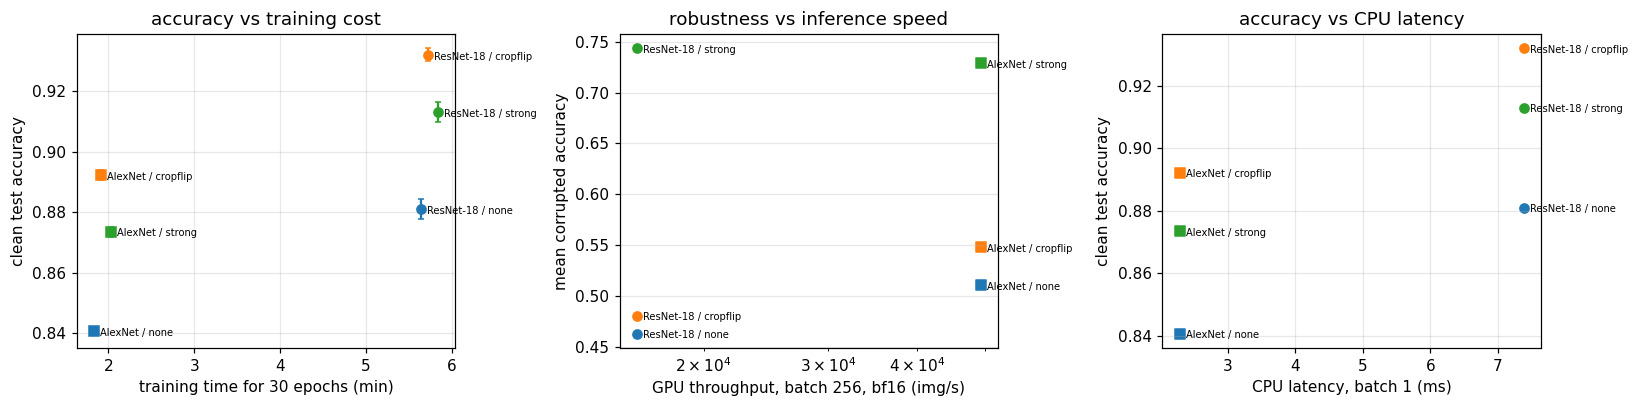

In [37]:
rows = []
for arch, label in [("alexnet", "AlexNet"), ("resnet18", "ResNet-18")]:
    for aug in AUG_CONDITIONS:
        names = [f"{arch}_{aug}_s{s}" for s in SEEDS]
        rows.append({
            "config": f"{label} / {aug}",
            "params (M)": RUNS[names[0]].summary["params"] / 1e6,
            "MMACs": arch_cost.loc[label, "MMACs / image"],
            "train time (min)": np.mean([RUNS[n].summary["train_seconds"] for n in names]) / 60,
            "peak train mem (MB)": np.mean([RUNS[n].summary["peak_memory_mb"] for n in names]),
            "test acc": rob_mean.loc[(arch, aug), ("clean", "")],
            "test acc std": rob_std.loc[(arch, aug), ("clean", "")],
            "corrupted acc": rob_mean.loc[(arch, aug), ("mean corrupted", "")],
            "PGD acc @2/255": adv[(adv.model == names[0]) & (adv["eps (x/255)"] == 2)]["PGD acc"].item(),
            "GPU b1 latency fp32 (ms)": timing.loc[label, "GPU fp32 b1 latency (ms)"],
            "GPU b256 bf16 (img/s)": timing.loc[label, "GPU bf16 b256 throughput (img/s)"],
            "CPU b1 latency (ms)": timing.loc[label, "CPU fp32 b1 latency (ms)"],
        })
tradeoff = pd.DataFrame(rows).set_index("config")
display(tradeoff)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for k, (cfg_name, r) in enumerate(tradeoff.iterrows()):
    marker = "o" if cfg_name.startswith("ResNet") else "s"
    colour = f"C{AUG_CONDITIONS.index(cfg_name.split(' / ')[1])}"
    axes[0].errorbar(r["train time (min)"], r["test acc"], yerr=r["test acc std"], fmt=marker, color=colour, capsize=2)
    axes[0].annotate(cfg_name, (r["train time (min)"], r["test acc"]), fontsize=6.5, xytext=(4, -3), textcoords="offset points")
    axes[1].scatter(r["GPU b256 bf16 (img/s)"], r["corrupted acc"], marker=marker, color=colour)
    axes[1].annotate(cfg_name, (r["GPU b256 bf16 (img/s)"], r["corrupted acc"]), fontsize=6.5, xytext=(4, -3), textcoords="offset points")
    axes[2].scatter(r["CPU b1 latency (ms)"], r["test acc"], marker=marker, color=colour)
    axes[2].annotate(cfg_name, (r["CPU b1 latency (ms)"], r["test acc"]), fontsize=6.5, xytext=(4, -3), textcoords="offset points")
axes[0].set(xlabel="training time for 30 epochs (min)", ylabel="clean test accuracy", title="accuracy vs training cost")
axes[1].set(xscale="log", xlabel="GPU throughput, batch 256, bf16 (img/s)", ylabel="mean corrupted accuracy", title="robustness vs inference speed")
axes[2].set(xlabel="CPU latency, batch 1 (ms)", ylabel="clean test accuracy", title="accuracy vs CPU latency")
fig.tight_layout()
plt.show()

### 6.4 Sensitivity to seed, training duration and hardware
* **Seed:** spread over the three seeds per configuration, and whether the AlexNet/ResNet ranking holds for every seed pairing.
* **Training duration:** best validation accuracy with the shortened 10-epoch schedule (2.4, same peak learning rate) against the 30-epoch budget.
* **Hardware and precision:** ratio of ResNet-18 to AlexNet cost on each device and precision.

In [38]:
clean_by_run = rob_test[("clean", "")]
seed_view = clean_by_run.groupby([n.rsplit("_", 1)[0] for n in clean_by_run.index]).agg(["min", "max", "std"])
display(seed_view)
for aug in AUG_CONDITIONS:
    a = rob_test.loc[[f"alexnet_{aug}_s{s}" for s in SEEDS], ("clean", "")].values
    r = rob_test.loc[[f"resnet18_{aug}_s{s}" for s in SEEDS], ("clean", "")].values
    print(f"{aug}: ResNet-18 better than AlexNet in {(r[:, None] > a[None, :]).sum()} of 9 seed pairings")

duration = pd.DataFrame({
    "10-epoch schedule": {a: RUNS[f"lrcheck_{a}_lr{LR[a]}"].summary["best_val_accuracy"] for a in ["alexnet", "resnet18"]},
    "30-epoch schedule (seed 0)": {a: RUNS[f"{a}_none_s0"].summary["best_val_accuracy"] for a in ["alexnet", "resnet18"]},
    "30-epoch: val acc after epoch 10": {a: RUNS[f"{a}_none_s0"].history.val_accuracy.iloc[9] for a in ["alexnet", "resnet18"]},
})
display(duration)

ratio = (timing.loc["ResNet-18"] / timing.loc["AlexNet"]).to_frame("ResNet-18 / AlexNet")
display(ratio)

,min,max,std
alexnet_cropflip,0.8910,0.8941,0.0017
alexnet_none,0.8401,0.8417,0.0009
alexnet_strong,0.8716,0.8748,0.0017
resnet18_cropflip,0.9302,0.9344,0.0022
resnet18_none,0.8773,0.8831,0.0032
resnet18_strong,0.9099,0.9166,0.0034


none: ResNet-18 better than AlexNet in 9 of 9 seed pairings
cropflip: ResNet-18 better than AlexNet in 9 of 9 seed pairings
strong: ResNet-18 better than AlexNet in 9 of 9 seed pairings


,10-epoch schedule,30-epoch schedule (seed 0),30-epoch: val acc after epoch 10
alexnet,0.8368,0.8468,0.8032
resnet18,0.8828,0.8922,0.7296


,ResNet-18 / AlexNet
GPU fp32 b1 latency (ms),3.4792
GPU fp32 b256 throughput (img/s),0.2864
GPU bf16 b1 latency (ms),4.1925
GPU bf16 b256 throughput (img/s),0.3265
GPU fp16 b1 latency (ms),4.2123
GPU fp16 b256 throughput (img/s),0.3081
CPU fp32 b1 latency (ms),3.2272
CPU fp32 b64 throughput (img/s),0.2857


## Challenge 1. Model Compression
**Reference and goal.** The reference is the seed-0 ResNet-18 with the best validation accuracy among the three training conditions. The goal is a model that is faster at inference on this laptop (GPU batch-256 throughput and CPU batch-1 latency) while losing at most **1 percentage point** of clean test accuracy. Parameter count and file size are reported separately from speed.

**Methods.**
1. *FP16 weights*: cast the trained model to half precision, no retraining.
2. *Magnitude pruning*: remove the 80% conv and linear weights with the smallest absolute value (one global threshold), then fine-tune for 5 epochs (peak lr 0.01, same augmentation) with the mask re-applied after every step. The tensors stay dense, so this reduces the number of non-zero weights and the compressed file size, but not necessarily the run time.
3. *Knowledge distillation* into smaller dense ResNets: ResNet-10 (full width) and ResNet-10 at half width, trained for the same 30 epochs with the soft targets of the reference model (temperature 4, weight 0.9 on the distillation term). Each student is also trained without the teacher to measure what distillation adds.

In [39]:
REFERENCE = max([f"resnet18_{aug}_s0" for aug in AUG_CONDITIONS], key=lambda n: RUNS[n].summary["best_val_accuracy"])
ref_run = RUNS[REFERENCE]
print("reference model:", REFERENCE)


def file_size_mb(state_dict, compressed=False):
    import io, zlib
    buf = io.BytesIO()
    torch.save(state_dict, buf)
    data = buf.getvalue()
    return len(zlib.compress(data, 6)) / 2 ** 20 if compressed else len(data) / 2 ** 20


def nonzero_params(model):
    return sum(int((p != 0).sum()) for p in model.parameters())


def magnitude_prune_and_finetune(source, sparsity=0.8, epochs=5, lr=0.01):
    cfg = replace(source.cfg, name=f"{source.cfg.name}_pruned{int(sparsity * 100)}", epochs=epochs, lr=lr, warmup_epochs=0)
    run_dir = RUN_ROOT / cfg.name
    model = build_model(cfg)
    model.load_state_dict(source.model.state_dict())
    weights = [p for p in model.parameters() if p.ndim > 1]
    magnitudes = torch.cat([w.detach().abs().flatten() for w in weights]).float().cpu()
    threshold = magnitudes.kthvalue(int(sparsity * len(magnitudes))).values
    masks = [(w.detach().abs() > threshold.to(w.device)).float() for w in weights]
    if REUSE_RUNS and (run_dir / "model.pt").exists() and json.loads((run_dir / "config.json").read_text()) == asdict(cfg):
        model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device, weights_only=True))
        return model, json.loads((run_dir / "summary.json").read_text())
    with torch.no_grad():
        for w, m in zip(weights, masks):
            w.mul_(m)
    pruned_acc = evaluate(model, splits["val"].x, splits["val"].y)["accuracy"]
    set_seed(cfg.seed)
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    opt = torch.optim.SGD([{"params": decay, "weight_decay": cfg.weight_decay}, {"params": no_decay, "weight_decay": 0}],
                          lr=lr, momentum=0.9, nesterov=True)
    n = len(splits["train"].y)
    steps = epochs * math.ceil(n / cfg.batch_size)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor(steps, 0))
    gen = torch.Generator(device=device).manual_seed(cfg.seed)
    synchronize(); t0 = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(n, device=device, generator=gen)
        for start in range(0, n, cfg.batch_size):
            idx = order[start:start + cfg.batch_size]
            xb = AUGMENTATIONS[cfg.augment](to_float(splits["train"].x[idx]), gen)
            with torch.autocast(device.type, dtype=AMP_DTYPE):
                loss = F.cross_entropy(model(xb).float(), splits["train"].y[idx])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            with torch.no_grad():
                for w, m in zip(weights, masks):
                    w.mul_(m)
    synchronize()
    summary = {"sparsity": sparsity, "val acc right after pruning": pruned_acc,
               "val acc after fine-tuning": evaluate(model, splits["val"].x, splits["val"].y)["accuracy"],
               "fine-tune seconds": time.perf_counter() - t0}
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), run_dir / "model.pt")
    (run_dir / "summary.json").write_text(json.dumps(summary, indent=2))
    (run_dir / "config.json").write_text(json.dumps(asdict(cfg), indent=2))
    return model, summary


pruned_model, prune_summary = magnitude_prune_and_finetune(ref_run)
display(pd.Series(prune_summary))

students = {}
for arch, width in [("resnet10", 1.0), ("resnet10", 0.5)]:
    base = RunConfig(f"{arch}_w{width}_{ref_run.cfg.augment}_s0", arch, width=width, lr=LR[arch], augment=ref_run.cfg.augment)
    students[f"{arch} x{width} scratch"] = train_run(base)
    students[f"{arch} x{width} distilled"] = train_run(replace(base, name=base.name + "_kd", teacher=REFERENCE))

reference model: resnet18_cropflip_s0


sparsity                        0.8000
val acc right after pruning     0.9238
val acc after fine-tuning       0.9322
fine-tune seconds              57.0594
dtype: float64

[resnet10_w1.0_cropflip_s0] loaded from cache: best val acc 0.9282 (epoch 29)
[resnet10_w1.0_cropflip_s0_kd] loaded from cache: best val acc 0.9370 (epoch 29)
[resnet10_w0.5_cropflip_s0] loaded from cache: best val acc 0.9092 (epoch 30)
[resnet10_w0.5_cropflip_s0_kd] loaded from cache: best val acc 0.9272 (epoch 29)


In [40]:
@torch.inference_mode()
def plain_accuracy(m, x_uint8, y):
    """Accuracy without autocast, in the model's own dtype (FP32, or FP16 after .half())."""
    m.eval()
    dtype = next(m.parameters()).dtype
    pred = torch.cat([m(to_float(x_uint8[i:i + 1000]).to(dtype)).argmax(1) for i in range(0, len(x_uint8), 1000)])
    return (pred == y).float().mean().item()


def compression_row(label, model, extra_seconds, t, fp16=False):
    """t: timing row of `model` from benchmark(); the FP16 row uses the fp16 columns of the reference."""
    m = copy.deepcopy(model).eval()
    if fp16:
        m = m.half()
    acc = plain_accuracy(m, splits["test"].x, splits["test"].y)
    corr = np.mean([plain_accuracy(m, xc, splits["test"].y) for xc in corrupted["test"].values()])
    sd = m.state_dict()
    return {"model": label, "test acc": acc, "change (pp)": 100 * (acc - ref_acc), "mean corrupted acc": corr,
            "params (M)": count_params(model.net) / 1e6, "non-zero params (M)": nonzero_params(model.net) / 1e6,
            "file (MB)": file_size_mb(sd), "file zlib (MB)": file_size_mb(sd, compressed=True),
            "GPU b256 throughput (img/s)": t[f"GPU {'fp16' if fp16 else 'bf16'} b256 throughput (img/s)"],
            "GPU b1 latency (ms)": t[f"GPU {'fp16' if fp16 else 'fp32'} b1 latency (ms)"],
            "CPU b1 latency (ms)": t["CPU fp32 b1 latency (ms)"],
            "extra compute (GPU min)": extra_seconds / 60}


ref_label, prune_label = f"reference ({REFERENCE})", "80% magnitude pruned + 5 ep fine-tune"
comp_models = {ref_label: ref_run.model, prune_label: pruned_model, **{label: run.model for label, run in students.items()}}
comp_timing, _ = benchmark(comp_models)

ref_acc = plain_accuracy(ref_run.model, splits["test"].x, splits["test"].y)
comp_rows = [compression_row(ref_label, ref_run.model, 0.0, comp_timing.loc[ref_label]),
             compression_row("FP16 weights", ref_run.model, 0.0, comp_timing.loc[ref_label], fp16=True),
             compression_row(prune_label, pruned_model, prune_summary["fine-tune seconds"], comp_timing.loc[prune_label])]
for label, run in students.items():
    comp_rows.append(compression_row(label, run.model, run.summary["train_seconds"], comp_timing.loc[label]))
compression = pd.DataFrame(comp_rows).set_index("model")
compression["within 1 pp"] = compression["change (pp)"] >= -1.0
display(compression)
print("Accuracies in this table are computed without autocast: FP32, and FP16 for the FP16 row. GPU throughput uses "
      "bf16 autocast for all rows except the FP16 row (pure FP16); GPU latency is FP32 except the FP16 row; "
      "CPU latency is always FP32.")

,test acc,change (pp),mean corrupted acc,params (M),non-zero params (M),file (MB),file zlib (MB),GPU b256 throughput (img/s),GPU b1 latency (ms),CPU b1 latency (ms),extra compute (GPU min),within 1 pp
model,,,,,,,,,,,,
reference (resnet18_cropflip_s0),0.9316,0.00,0.4756,11.1740,11.1740,42.7013,39.5362,16168.1590,2.5792,7.5644,0.0000,True
FP16 weights,0.9316,0.00,0.4756,11.1740,11.1740,21.3704,19.6576,16109.1293,1.8014,7.5644,0.0000,True
80% magnitude pruned + 5 ep fine-tune,0.9327,0.11,0.4821,11.1740,2.2425,42.7013,11.3606,16375.9928,2.3058,8.4852,0.9510,True
resnet10 x1.0 scratch,0.9165,-1.51,0.4758,4.9032,4.9032,18.7505,17.4085,31789.3953,1.9325,4.8757,2.9765,False
resnet10 x1.0 distilled,0.9326,0.10,0.4851,4.9032,4.9032,18.7505,17.4039,31791.2902,1.3583,4.2648,4.6108,True
resnet10 x0.5 scratch,0.9092,-2.24,0.4810,1.2290,1.2290,4.7233,4.3746,97982.5545,1.2539,3.0962,1.2962,False
resnet10 x0.5 distilled,0.9216,-1.00,0.4677,1.2290,1.2290,4.7233,4.3739,98373.3808,1.3248,2.9997,2.9548,True


Accuracies in this table are computed without autocast: FP32, and FP16 for the FP16 row. GPU throughput uses bf16 autocast for all rows except the FP16 row (pure FP16); GPU latency is FP32 except the FP16 row; CPU latency is always FP32.


## Challenge 2. Generalization Beyond the Development Conditions
**Shifts.** None of these were used for training, augmentation design or model selection.
1. *Unseen corruption families* on the same 10,000 test images (paired with the clean images): JPEG compression (quality 30, 15, 8), pixelation (downsample to 20, 16, 12 pixels with area averaging and upsample with nearest neighbour) and contrast reduction (pixel values pulled towards the image mean with factor 0.5, 0.3, 0.15). These are "digital" corruptions in the style of CIFAR-10-C, unlike the geometric, noise and blur families of Task 4.
2. *A new image sample:* CIFAR-10.1 v6 (Recht et al., 2018), 2,000 new 32x32 images collected from the same source (Tiny Images) with the same ten classes and labelling procedure. The labels are directly compatible and the images use the same format, so the preprocessing is unchanged. These images are not paired with CIFAR-10 test images, so I compare accuracies with a bootstrap confidence interval.

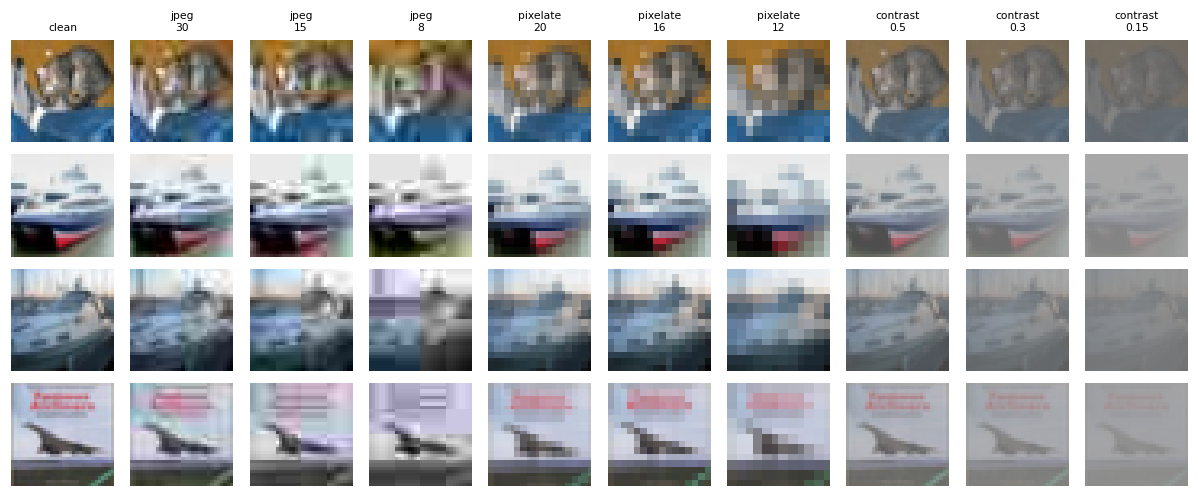

clean    jpeg                 pixelate                  \
                                  30      15       8       20      16      12   
run                                                                             
alexnet_none_s0       0.8401  0.7669  0.7125  0.6034   0.6412  0.6239  0.4414   
alexnet_cropflip_s0   0.8941  0.7857  0.7022  0.5647   0.6105  0.5803  0.3841   
alexnet_strong_s0     0.8742  0.7916  0.7294  0.6138   0.7402  0.7120  0.5448   
resnet18_none_s0      0.8827  0.6275  0.5050  0.3695   0.3499  0.3445  0.2384   
resnet18_cropflip_s0  0.9315  0.6530  0.5116  0.3610   0.3213  0.3113  0.2169   
resnet18_strong_s0    0.9127  0.7705  0.6658  0.4678   0.5228  0.4997  0.2890   

                     contrast                 mean corrupted  
                          0.5     0.3    0.15                 
run                                                           
alexnet_none_s0        0.7285  0.4183  0.1605         0.5663  
alexnet_cropflip_s0    0.7929  0.4621  0.1731         0.5617  
alexnet_strong_s0      0.8176  0.5755  0.2197         0.6383  
resnet18_none_s0       0.8194  0.6430  0.2512         0.4609  
resnet18_cropflip_s0   0.8864  0.7192  0.2272         0.4675  
resnet18_strong_s0     0.8819  0.7768  0.3817         0.5840

In [41]:
import io
from PIL import Image


def jpeg(x_uint8, quality):
    out = []
    for img in x_uint8.permute(0, 2, 3, 1).cpu().numpy():
        buf = io.BytesIO()
        Image.fromarray(img).save(buf, format="JPEG", quality=quality)
        out.append(np.asarray(Image.open(buf).convert("RGB")))
    return torch.from_numpy(np.stack(out)).permute(0, 3, 1, 2).contiguous().to(device)


def pixelate(x_uint8, size):
    x = x_uint8.float()
    small = F.interpolate(x, size=(size, size), mode="area")
    return F.interpolate(small, size=(32, 32), mode="nearest").round().clamp(0, 255).to(torch.uint8)


def contrast(x_uint8, factor):
    x = x_uint8.float()
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - mean) * factor + mean).round().clamp(0, 255).to(torch.uint8)


UNSEEN = {"jpeg": (jpeg, [30, 15, 8]), "pixelate": (pixelate, [20, 16, 12]), "contrast": (contrast, [0.5, 0.3, 0.15])}
unseen_sets = {(fam, lv): fn(splits["test"].x, lv) for fam, (fn, levels) in UNSEEN.items() for lv in levels}

fig, axes = plt.subplots(4, 10, figsize=(11, 4.6))
for r in range(4):
    axes[r, 0].imshow(splits["test"].x[r].permute(1, 2, 0).cpu())
    for c, key in enumerate(unseen_sets):
        axes[r, c + 1].imshow(unseen_sets[key][r].permute(1, 2, 0).cpu())
        if r == 0:
            axes[r, c + 1].set_title(f"{key[0]}\n{key[1]}", fontsize=7)
axes[0, 0].set_title("clean", fontsize=7)
for ax in axes.flat:
    ax.axis("off")
fig.tight_layout()
plt.show()

unseen_table = robustness_table(main_models, "test", sets=unseen_sets)
display(unseen_table)

In [42]:
C101_URL = "https://github.com/modestyachts/CIFAR-10.1/raw/master/datasets/"
c101_dir = DATA_ROOT / "cifar10.1"
c101_dir.mkdir(exist_ok=True)
for f in ["cifar10.1_v6_data.npy", "cifar10.1_v6_labels.npy"]:
    if not (c101_dir / f).exists():
        urllib.request.urlretrieve(C101_URL + f, c101_dir / f)
X_c101 = np.load(c101_dir / "cifar10.1_v6_data.npy")
y_c101 = np.load(c101_dir / "cifar10.1_v6_labels.npy").astype(np.int64)
print("CIFAR-10.1:", X_c101.shape, X_c101.dtype, "class counts:", np.bincount(y_c101, minlength=10))
splits["cifar10.1"] = make_split(X_c101, y_c101, np.arange(len(X_c101)))


def bootstrap_ci(correct, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = rng.choice(correct, size=(n_boot, len(correct)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


rows = []
for n in main_models:
    c10 = (evaluate(RUNS[n].model, splits["test"].x, splits["test"].y)["pred"] == splits["test"].y).cpu().numpy()
    c101 = (evaluate(RUNS[n].model, splits["cifar10.1"].x, splits["cifar10.1"].y)["pred"] == splits["cifar10.1"].y).cpu().numpy()
    lo, hi = bootstrap_ci(c101)
    rows.append({"model": n, "CIFAR-10 test acc": c10.mean(), "CIFAR-10.1 acc": c101.mean(),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "gap (pp)": 100 * (c101.mean() - c10.mean())})
c101_table = pd.DataFrame(rows).set_index("model")
display(c101_table)

CIFAR-10.1: (2000, 32, 32, 3) uint8 class counts: [200 200 200 200 200 200 200 200 200 200]


,CIFAR-10 test acc,CIFAR-10.1 acc,95% CI,gap (pp)
model,,,,
alexnet_none_s0,0.8401,0.7160,"[0.696, 0.735]",-12.41
alexnet_cropflip_s0,0.8941,0.8025,"[0.784, 0.820]",-9.16
alexnet_strong_s0,0.8742,0.7610,"[0.742, 0.780]",-11.32
resnet18_none_s0,0.8827,0.7880,"[0.769, 0.805]",-9.47
resnet18_cropflip_s0,0.9315,0.8510,"[0.835, 0.867]",-8.05
resnet18_strong_s0,0.9127,0.8105,"[0.793, 0.829]",-10.22


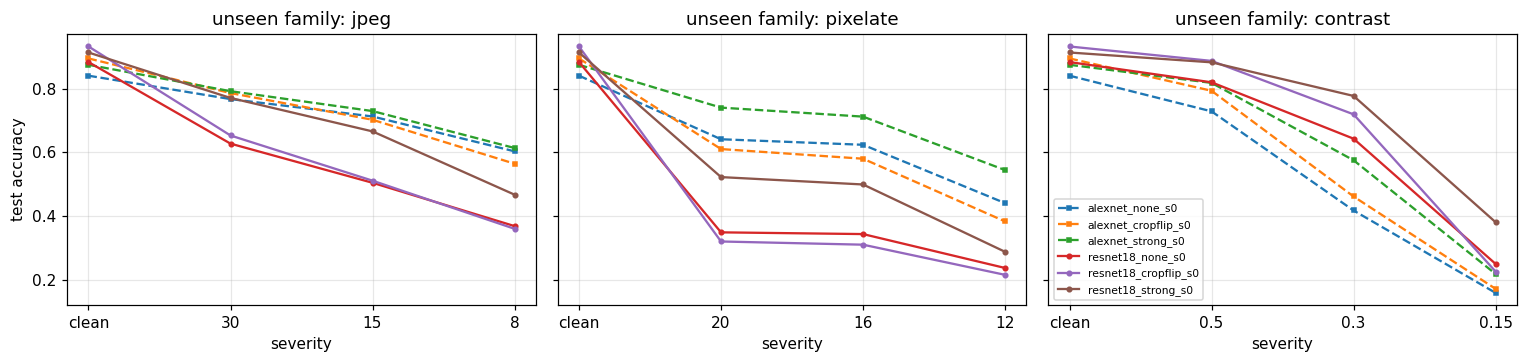

,CIFAR-10 recall,CIFAR-10.1 recall,change
airplane,0.938,0.820,-0.118
automobile,0.974,0.795,-0.179
bird,0.916,0.845,-0.071
cat,0.821,0.775,-0.046
deer,0.949,0.880,-0.069
dog,0.903,0.810,-0.093
frog,0.962,0.900,-0.062
horse,0.939,0.900,-0.039
ship,0.961,0.880,-0.081
truck,0.952,0.905,-0.047


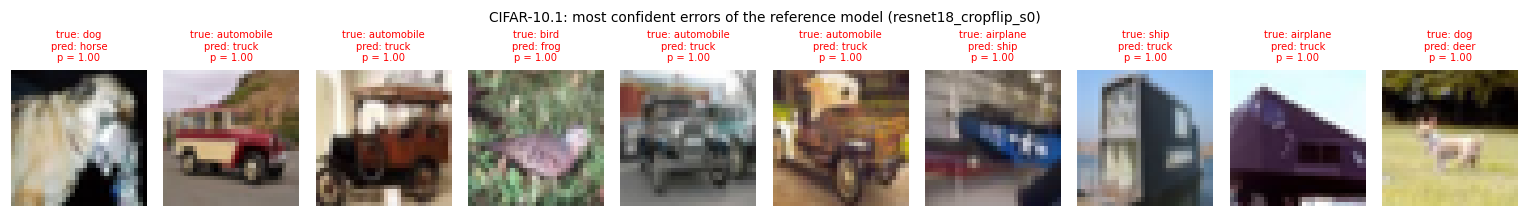

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, (family, (_, levels)) in zip(axes, UNSEEN.items()):
    for k, n in enumerate(main_models):
        vals = [unseen_table.loc[n, ("clean", "")]] + [unseen_table.loc[n, (family, lv)] for lv in levels]
        ax.plot(range(4), vals, "o-" if "resnet" in n else "s--", color=f"C{k}", label=n, ms=3)
    ax.set_xticks(range(4)); ax.set_xticklabels(["clean"] + [str(l) for l in levels])
    ax.set(title=f"unseen family: {family}", xlabel="severity")
axes[0].set_ylabel("test accuracy")
axes[-1].legend(fontsize=7)
fig.tight_layout()
plt.show()

ref_model = RUNS[REFERENCE].model
c101_pred = evaluate(ref_model, splits["cifar10.1"].x, splits["cifar10.1"].y)["pred"].cpu().numpy()
recall_c10 = [(test_out[REFERENCE]["pred"][y_test_np == c] == c).mean() for c in range(10)]
recall_c101 = [(c101_pred[y_c101 == c] == c).mean() for c in range(10)]
display(pd.DataFrame({"CIFAR-10 recall": recall_c10, "CIFAR-10.1 recall": recall_c101,
                      "change": np.subtract(recall_c101, recall_c10)}, index=class_names))

c101_probs = predict_logits(ref_model, splits["cifar10.1"].x).softmax(1).cpu().numpy()
wrong = np.flatnonzero(c101_pred != y_c101)
worst = wrong[np.argsort(c101_probs[wrong].max(1))[::-1][:10]]
fig, axes = plt.subplots(1, 10, figsize=(14, 2.1))
for ax, i in zip(axes, worst):
    ax.imshow(X_c101[i])
    ax.set_title(f"true: {class_names[y_c101[i]]}\npred: {class_names[c101_pred[i]]}\np = {c101_probs[i].max():.2f}",
                 fontsize=6.5, color="red")
    ax.axis("off")
fig.suptitle(f"CIFAR-10.1: most confident errors of the reference model ({REFERENCE})", fontsize=9)
fig.tight_layout()
plt.show()

## References
* A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, 2009 (CIFAR-10). https://www.cs.toronto.edu/~kriz/cifar.html
* A. Krizhevsky, I. Sutskever, G. Hinton, *ImageNet Classification with Deep Convolutional Neural Networks*, NeurIPS 2012.
* K. He, X. Zhang, S. Ren, J. Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016. https://arxiv.org/abs/1512.03385
* K. He et al., *Delving Deep into Rectifiers* (He initialisation), ICCV 2015.
* I. Goodfellow, J. Shlens, C. Szegedy, *Explaining and Harnessing Adversarial Examples* (FGSM), ICLR 2015.
* A. Madry et al., *Towards Deep Learning Models Resistant to Adversarial Attacks* (PGD), ICLR 2018.
* D. Hendrycks, T. Dietterich, *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations* (CIFAR-10-C), ICLR 2019.
* B. Recht, R. Roelofs, L. Schmidt, V. Shankar, *Do CIFAR-10 Classifiers Generalize to CIFAR-10?*, 2018 (CIFAR-10.1). https://github.com/modestyachts/CIFAR-10.1
* G. Hinton, O. Vinyals, J. Dean, *Distilling the Knowledge in a Neural Network*, 2015.
* S. Han, J. Pool, J. Tran, W. Dally, *Learning both Weights and Connections for Efficient Neural Networks* (magnitude pruning), NeurIPS 2015.
* C. Guo, G. Pleiss, Y. Sun, K. Weinberger, *On Calibration of Modern Neural Networks* (ECE), ICML 2017.
* S. Ioffe, C. Szegedy, *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*, ICML 2015.
* N. Srivastava et al., *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*, JMLR 2014.
* ID2223 Lab 2 notebook (Part A), PyTorch documentation for `nn.Conv2d`, `torch.autocast`, the reproducibility notes (https://pytorch.org/docs/stable/notes/randomness.html) and the FGSM tutorial.